## EDA - Matilde: behaviour, value and feature engineering

**Scope (from the work plan):** usage, add-ons, value, engineered features, first look at possible groups.

**Conventions shared with the group:** `df_original` (raw copy), `df_raw`, `df_clean`, snake_case features,
`metric_features` / `non_metric_features` lists.


## Setup 

In [43]:
# Remember: library imports are ALWAYS at the top of the script, no exceptions!
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# for better resolution plots
%config InlineBackend.figure_format = 'retina'

# plot style used in all figures of this notebook
sns.set_theme(style="whitegrid")

# Paths to the data (relative to notebooks/drafts/). Both files use ";" as separator.
RAW_PATH = os.path.join("..", "..", "data", "acdc_dataset.csv")
CLEAN_PATH = os.path.join("..", "..", "data", "acdc_clean.csv")    # saved by Martim's notebook (section 10)

# Columns that must be read as dates
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]

# Day the data was extracted. Martim found it in section 5.6 of his notebook
# (placeholder end dates + days_since_last_visit point to this date).
EXTRACTION_DATE = pd.Timestamp("2024-01-01")

# Plan tiers in the order given by the metadata (hot_desk < flex < dedicated_desk < full_time < private_office)
TIER_ORDER = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

## Functions

All functions are defined here, at the beginning, and called later in the notebook.

| Function | What it does |
|---|---|
| `plot_hist_box(data, features, title)` | Histogram (top row) and box plot (bottom row) for each feature |
| `engineer_features(data, extraction_date)` | Creates all the engineered features of section 4 and returns a new dataframe |

In [44]:
def plot_hist_box(data, features, title, bins=30):
    '''Histogram (top row) and box plot (bottom row) of each feature, side by side.'''
    fig, axes = plt.subplots(2, len(features), figsize=(5 * len(features), 7), tight_layout=True, squeeze=False)
    for i, feat in enumerate(features):
        sns.histplot(data[feat], bins=bins, ax=axes[0, i])     # shape of the distribution
        axes[0, i].set_title(feat)
        sns.boxplot(x=data[feat], ax=axes[1, i])               # quartiles and outliers
    fig.suptitle(title)
    plt.show()


def engineer_features(data, extraction_date):
    '''Return a copy of `data` with the engineered features (formulas and justification in section 4).

    Ratios use NaN (not inf) when the denominator is 0, so those members are simply "undefined" for that feature.
    '''
    out = data.copy()
    addons = [c for c in out.columns if c.startswith("uses_")]

    # Loyalty: time as a member. Active members (no end date) are measured up to the extraction date.
    out["tenure_days"] = (out["membership_end"].fillna(extraction_date) - out["membership_start"]).dt.days

    # Recency at the extraction date, from the last badge swipe. (days_since_last_visit stops at membership_end
    # for members who left, so it is not a comparable recency for everyone.)
    out["recency_days"] = (extraction_date - out["last_badge_swipe"]).dt.days

    # Share of the entitled visits that the member really used (0 entitled visits -> undefined)
    out["utilization_rate"] = out["actual_visits_last_period"] / out["entitled_visits_last_period"].replace(0, np.nan)

    # Revenue per month of membership (tenure <= 0 -> undefined)
    tenure_months = (out["tenure_days"] / 30.44).where(out["tenure_days"] > 0)     # 30.44 = average days in a month
    out["ltv_per_month"] = out["lifetime_value"] / tenure_months

    # Revenue per month compared with the usual value of the member's tier:
    # ~1 = pays just the plan, >1 = pays for more than the plan (add-ons)
    out["ltv_vs_tier"] = out["ltv_per_month"] / out.groupby("plan_tier")["ltv_per_month"].transform("median")

    # How many different add-ons the member uses
    out["n_addons"] = out[addons].sum(axis=1)

    # Hours of meeting/event rooms per visit: separates "office/events" users from "just a desk" users
    out["hours_per_visit"] = (out["meeting_room_hours"] + out["event_space_hours"]) / out["total_visits"].replace(0, np.nan)

    # Active (no end date) vs churned
    out["is_active"] = out["membership_end"].isna().astype(int)

    # Plan tier as a number (metadata order: hot_desk=1 ... private_office=5)
    out["plan_tier_ord"] = out["plan_tier"].map({t: i + 1 for i, t in enumerate(TIER_ORDER)})

    # RFM scores, 1 (worst) to 5 (best). rank(method="first") avoids duplicate bin edges in qcut.
    # Recency: FEWER days since the last visit is better, so its labels are reversed.
    out["r_score"] = pd.qcut(out["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
    out["f_score"] = pd.qcut(out["avg_weekly_visits"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    out["m_score"] = pd.qcut(out["lifetime_value"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    out["rfm_score"] = out[["r_score", "f_score", "m_score"]].sum(axis=1)

    return out

## Reading the Data

In [45]:
# Raw data (kept untouched, only for before/after comparisons); the file uses ";" as separator
df_raw = pd.read_csv(RAW_PATH, sep=";")
df_original = df_raw.copy()

# Cleaned data from Martim's clean_data(): dates already parsed, no 1970 placeholder, no impossible values
df_clean = pd.read_csv(CLEAN_PATH, sep=";", parse_dates=date_cols)

print("raw:", df_raw.shape, "| clean:", df_clean.shape)
df_clean.head()

raw: (15465, 31) | clean: (15082, 31)


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000002,38.0,Male,Information Technology,Portugal,True,2.0,hot_desk,2,2023-11-24,...,False,False,False,True,False,False,False,False,0.0,165.86
1,CW000003,43.0,Male,Education,Germany,True,1.0,flex,3,2021-12-03,...,False,False,False,False,False,False,False,False,1.0,4486.17
2,CW000004,38.0,Female,Legal,Portugal,False,0.0,flex,3,2022-01-02,...,False,False,False,False,False,False,False,False,0.0,258.63
3,CW000005,45.0,Female,Information Technology,United Kingdom,False,0.0,hot_desk,2,2023-10-24,...,False,False,False,False,False,True,False,False,0.0,335.74
4,CW000006,39.0,Male,Health,Portugal,False,0.0,flex,3,2021-05-31,...,False,False,True,True,False,False,False,False,0.0,413.17


In [46]:
# Data types and non-null counts of the cleaned data
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15082 entries, 0 to 15081
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   member_id                    15082 non-null  object        
 1   age                          15082 non-null  float64       
 2   gender                       15082 non-null  object        
 3   industry                     15082 non-null  object        
 4   country                      15082 non-null  object        
 5   is_team_account              15082 non-null  bool          
 6   n_colleagues_on_account      15082 non-null  float64       
 7   plan_tier                    15082 non-null  object        
 8   plan_days_per_week           15082 non-null  int64         
 9   membership_start             15082 non-null  datetime64[ns]
 10  membership_end               11184 non-null  datetime64[ns]
 11  last_badge_swipe             15082 non-nu

## Feature groups

**What we do in this step:** we prepare the cleaned dataset (`df_clean`) for the analysis of behaviour and value.

1. **Convert the add-on flags to numbers.** The `uses_*` columns (meeting rooms, event space, guest passes, print, mail handling, phone booths, day passes, storage and bike locker) and `is_team_account` are stored as True/False. We convert them to 1/0 so that we can sum them (for example, how many add-ons each member uses) and compute correlations.
2. **Split the variables into two groups**, as in the labs:
   - *Non-metric features*: categories and flags (`gender`, `country`, `industry`, `plan_tier`, `is_team_account` and the add-on flags). It does not make sense to average them.
   - *Metric features*: numeric variables (`age`, visits, hours, renewals, `lifetime_value`, etc.). These are the ones we use in histograms, box plots and correlations.
3. **Check for missing values.** After the cleaning, the only column with missing values should be `membership_end`, which is empty on purpose for active members. If another column appears, we need to go back to the cleaning step.

In [47]:
# uses_* flags are True/False in the cleaned file -> make them 0/1 integers so they can be summed and correlated
addon_cols = [c for c in df_clean.columns if c.startswith("uses_")]
df_clean[addon_cols] = df_clean[addon_cols].astype(int)
df_clean["is_team_account"] = df_clean["is_team_account"].astype(int)

# Same split as in the labs: non-metric (categories/flags) vs metric (numbers)
non_metric_features = ["gender", "country", "industry", "plan_tier", "is_team_account"] + addon_cols
metric_features = ["age", "n_colleagues_on_account", "plan_days_per_week", "total_visits", "avg_weekly_visits",
                   "days_since_last_visit", "entitled_visits_last_period", "actual_visits_last_period",
                   "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]
print("add-on flags:", addon_cols)

# After the cleaning, only membership_end (empty = active member) should still have missing values
print("missing values left (only membership_end = active members is expected):")
print(df_clean.isna().sum()[lambda s: s > 0])

add-on flags: ['uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage', 'uses_bike_locker']
missing values left (only membership_end = active members is expected):
membership_end    3898
dtype: int64


### Impact of the data cleaning on this analysis

The cleaned dataset (`df_clean`) differs from the raw data in four ways that affect the behaviour and value analysis:

- **Active members have no end date.** The placeholder `1970-01-01` in `membership_end` was replaced by a missing value, which now means that the membership is still active.
- **`days_since_last_visit` is not a common recency measure.** It was recalculated up to `membership_end` for members who left, and up to the extraction date (2024-01-01) for active members. For churned members it therefore does not measure recency at the extraction date. For the RFM scores we compute our own `recency_days` from `last_badge_swipe` (see the feature engineering section).
- **Part of `lifetime_value` is estimated.** About 18.5% of the values were missing or invalid and were imputed as *monthly plan price × months of membership*. These values add no new information, and they inflate the relationship between `lifetime_value`, plan tier and tenure. We take this into account when interpreting the value analysis and the engineered features.
- **The plan tier order is not a price order.** The metadata lists `full_time` above `dedicated_desk`, but `dedicated_desk` has a higher monthly price. We keep this in mind when using `plan_tier` as an ordinal variable.

## 1. Usage

**Goal:** understand how often and how intensively members use the space, and whether they use what their plan entitles them to.

**What we analyse in this section:**
1. **Distribution of the usage variables** (`total_visits`, `avg_weekly_visits`, `days_since_last_visit`, `entitled_visits_last_period`, `actual_visits_last_period`). Histograms show the shape of each distribution and box plots show the quartiles and the outliers.
2. **Summary statistics** (mean, median, quartiles, minimum and maximum) to quantify what the plots show.
3. **Actual vs entitled visits in the last period.** Comparing the visits a member made with the visits the plan allows shows who uses less than they pay for. These members may be at risk of leaving.

**Why it matters for segmentation:** usage separates members who come every day from members who almost never come, even when they have the same plan. This is a behavioural signal that plan tier alone does not capture.

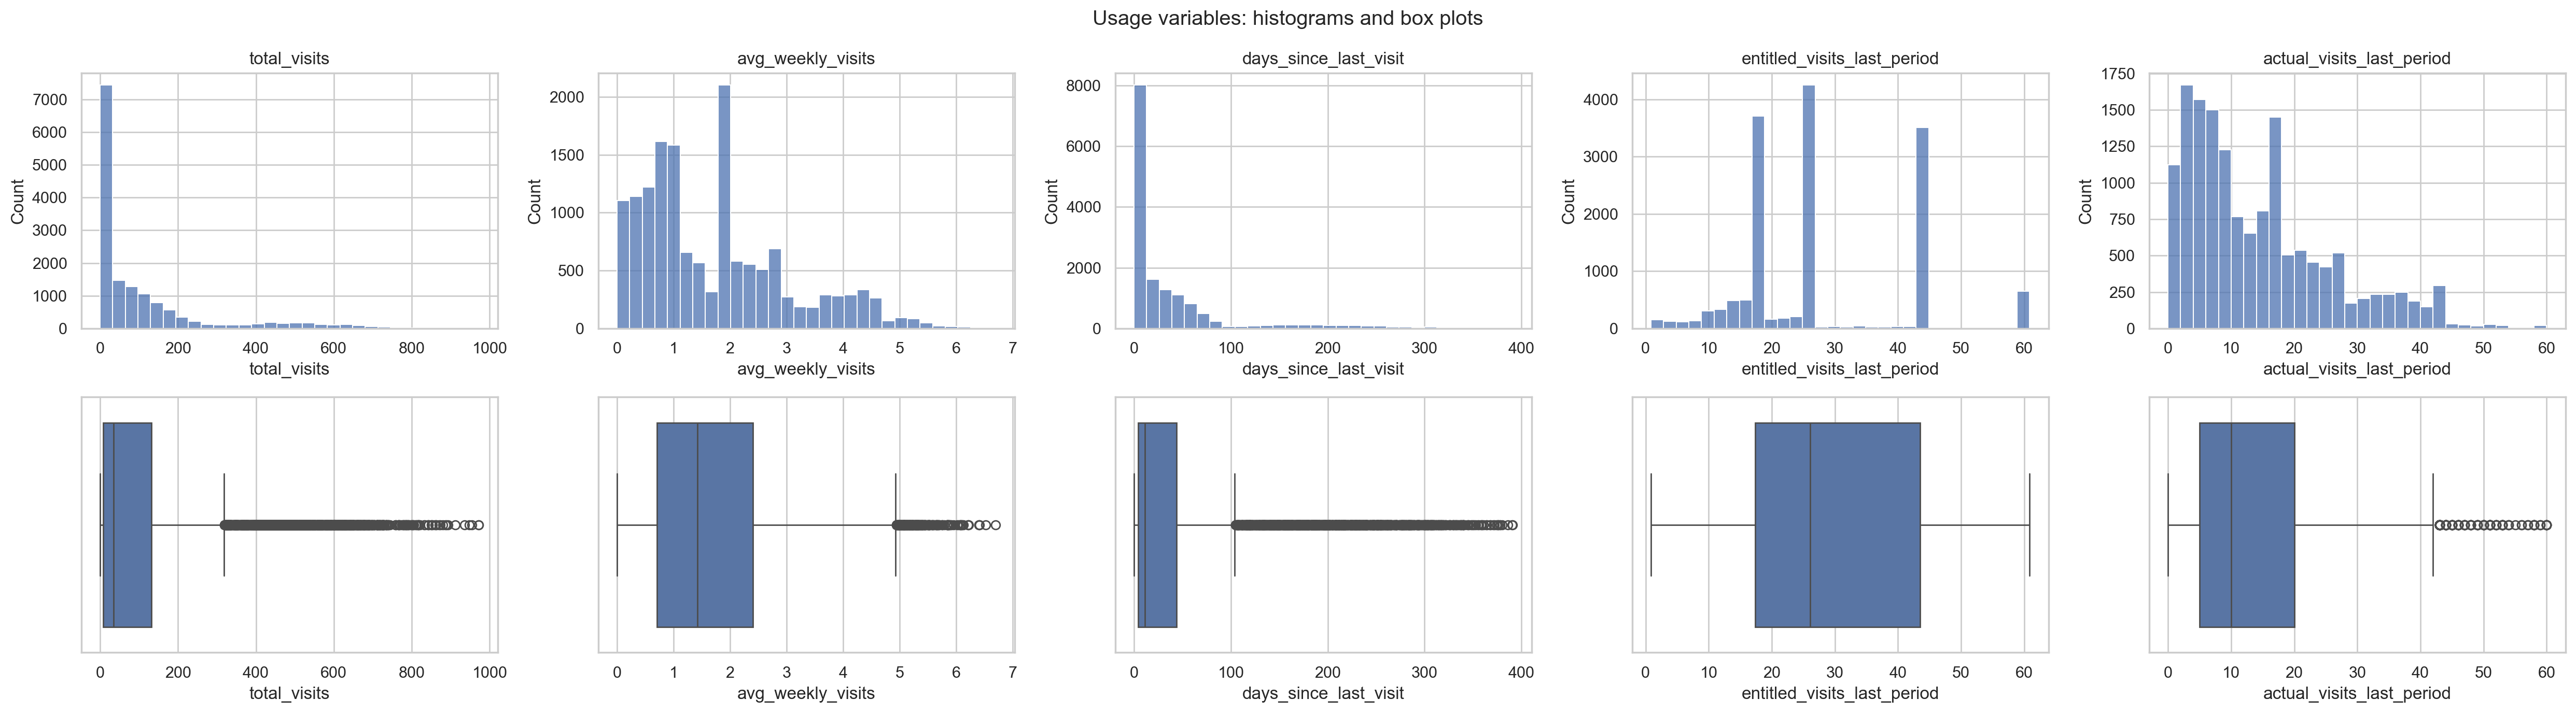

In [48]:
# Histogram and box plot of each usage variable (function defined in the Functions section)
usage_features = ["total_visits", "avg_weekly_visits", "days_since_last_visit",
                  "entitled_visits_last_period", "actual_visits_last_period"]

plot_hist_box(df_clean, usage_features, "Usage variables: histograms and box plots")

In [49]:
# Summary statistics of the usage variables: count, mean, std, min, quartiles (25/50/75%) and max
df_clean[usage_features].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
total_visits,15082.0,109.04,164.45,0.00,8.00,34.00,132.00,972.00
avg_weekly_visits,15082.0,1.71,1.29,0.00,0.71,1.42,2.40,6.70
days_since_last_visit,15082.0,37.77,61.57,0.00,4.00,11.00,44.00,391.00
entitled_visits_last_period,15082.0,27.41,13.28,0.87,17.39,26.09,43.48,60.87
actual_visits_last_period,15082.0,13.79,11.38,0.00,5.00,10.00,20.00,60.00


### Main takeaways - usage

- **Visits are strongly right-skewed.** The median member made 34 visits in total, but the mean is 109 and the maximum is 972. Most members visit rarely and a small group visits very often. The box plots show a long tail of outliers for `total_visits` and `days_since_last_visit`.
- **Weekly frequency is low for most members.** The median is 1.4 visits per week and 75% of members have 2.4 visits per week or fewer. The histogram has several peaks (around 1-1.5 and a sharp one at 2), which suggests different usage patterns.
- **Most members visited recently, but some have disappeared.** The median is 11 days since the last visit and 75% of members came in the last 44 days. The maximum is 391 days, so a group of members has not come for a long time.
- **Entitled visits come in discrete values.** The histogram has clear spikes (around 17, 26, 43 and 61), which correspond to the plan tiers (2, 3, 5 and 7 days per week).
- **Members use about half of what they are entitled to.** On average, members made 13.8 visits in the last period out of 27.4 entitled (median 10 vs 26). Many members therefore pay for more access than they use, which may be a churn risk.

### Last period: actual vs entitled visits

**What we do in this step:** each hexagon counts members. The red line marks members who used exactly what their plan entitles them to. Members below the line used less than they could, and members above used more.

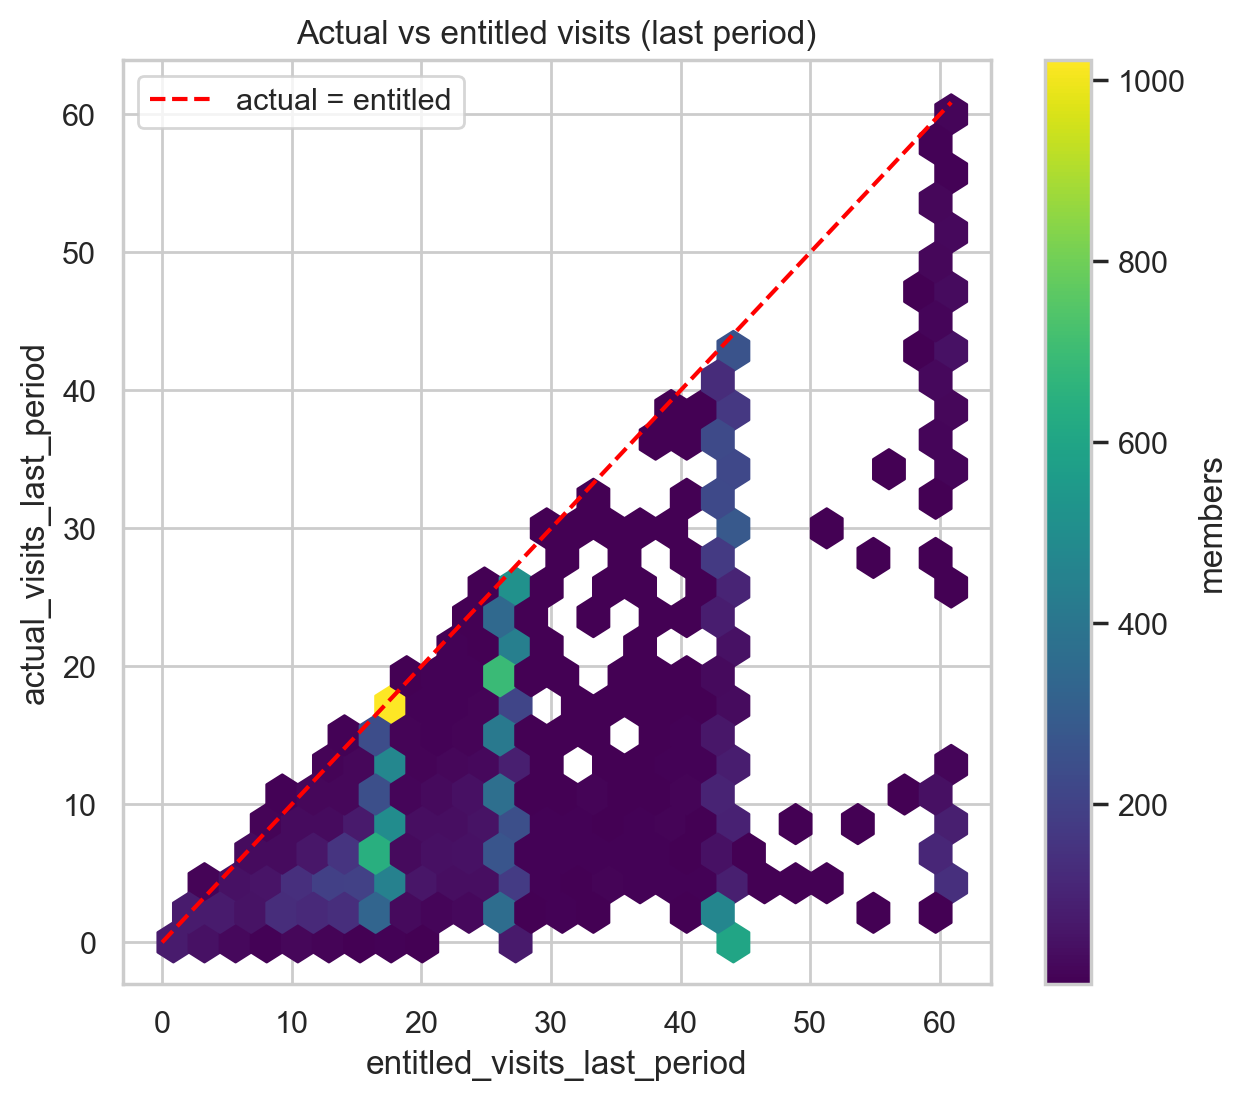

Share of members who exceeded their entitlement: 0.0 %


In [50]:
# Hexbin plot of entitled vs actual visits (hexagons are used instead of points because there are thousands of members)
fig, ax = plt.subplots(figsize=(7, 6))
hb = ax.hexbin(df_clean["entitled_visits_last_period"], df_clean["actual_visits_last_period"],
               gridsize=25, cmap="viridis", mincnt=1)

# reference line: actual = entitled
lim = max(df_clean["entitled_visits_last_period"].max(), df_clean["actual_visits_last_period"].max())
ax.plot([0, lim], [0, lim], color="red", linestyle="--", label="actual = entitled")
ax.set_xlabel("entitled_visits_last_period")
ax.set_ylabel("actual_visits_last_period")
ax.set_title("Actual vs entitled visits (last period)")
ax.legend()
fig.colorbar(hb, ax=ax, label="members")
plt.show()

# Share of members above their entitlement
exceeded = (df_clean["actual_visits_last_period"] > df_clean["entitled_visits_last_period"]).mean() * 100
print("Share of members who exceeded their entitlement:", round(exceeded, 2), "%")

### Main takeaways - actual vs entitled visits

- **No member exceeded their entitlement (0.0%).** Every hexagon is on or below the red line, so the plan works as a ceiling on visits. As a consequence, `utilization_rate` (actual / entitled) goes from 0 to 1.
- **Entitlements form vertical stripes** (around 17, 26, 43 and 61 visits), one per plan (2, 3, 5 and 7 days per week). Within each stripe, actual use goes from almost zero to the maximum, so **the plan tier does not tell how much a member really uses the space**.
- **There is a dense group on the red line**, mostly at the lowest entitlement (around 17 visits, the 2-day plan): these members use almost everything they pay for.
- **Many members are far below the line,** especially in the plans with more entitled visits. They pay for access they do not use, which may be a churn risk, and also an opportunity (for example, offering a cheaper plan or add-ons).
- **For segmentation:** utilization separates

## 2. Add-ons

**Goal:** understand which extra services members use, which ones are used together, and how much they use the meeting and event rooms.

**What we analyse in this section:**
1. **Adoption rate** of each add-on (% of members who use it).
2. **Co-usage and correlation** between add-ons, to see which ones go together.
3. **Meeting-room and event-space hours**, to see how intensively the rooms are used.
4. **Overview numbers (KPIs)** that summarise the member base.

**Why it matters for segmentation:** add-ons are a sign of how members use the space (just a desk vs an office with meetings and events), and they are paid on top of the plan.

### Adoption rate

**What we do in this step:** the mean of a 0/1 flag is the share of members who use that add-on, so we compute the mean of each `uses_*` column and sort the add-ons from the most to the least used.

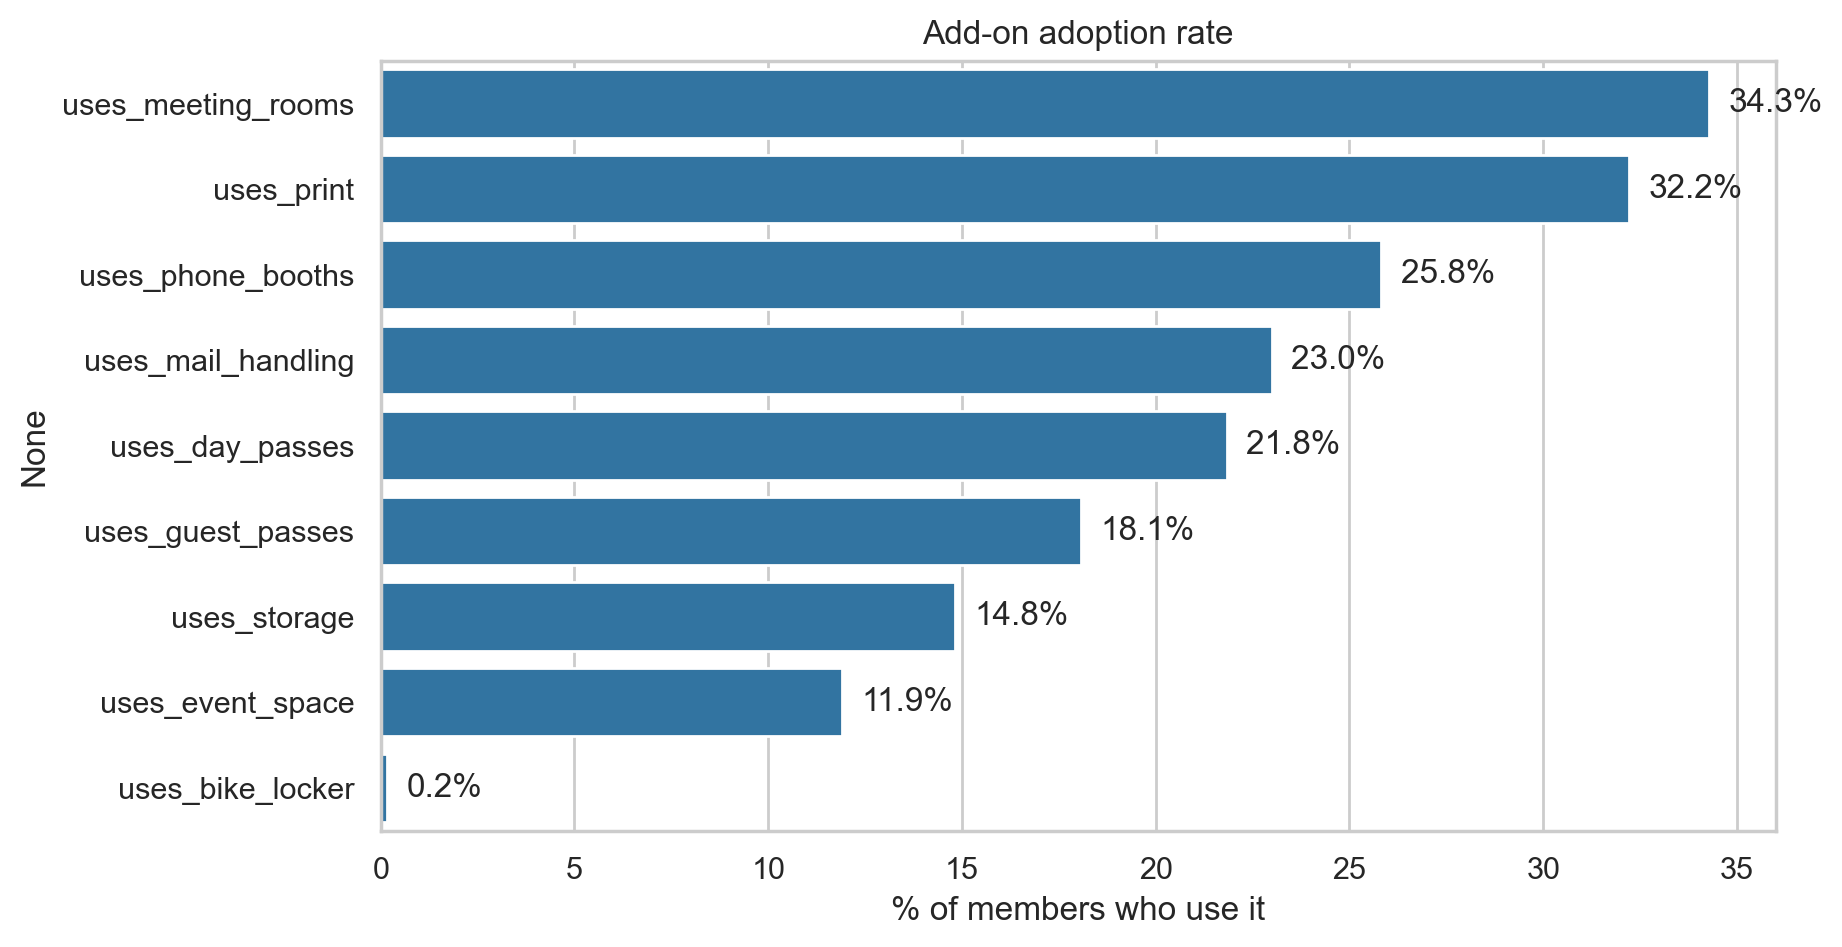

In [51]:
# Adoption rate = % of members who use each add-on (the mean of a 0/1 flag is the share of ones)
adoption = df_clean[addon_cols].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=adoption.values, y=adoption.index, ax=ax, color="tab:blue")
ax.set_xlabel("% of members who use it")
ax.set_title("Add-on adoption rate")

# write the percentage at the end of each bar
for p, v in zip(ax.patches, adoption.values):
    ax.text(v + 0.5, p.get_y() + p.get_height() / 2, f"{v:.1f}%", va="center")
plt.show()

**Reading the chart:**
- **No add-on is used by the majority of members.** The most used are meeting rooms (34.3%) and print (32.2%), so about one member in three uses each of them.
- **Phone booths (25.8%), mail handling (23.0%) and day passes (21.8%)** form a middle group used by roughly one member in four or five.
- **Guest passes (18.1%), storage (14.8%) and event space (11.9%) are niche services.**
- **The bike locker is almost not used (0.2%).** A variable that is almost always 0 carries very little information, so it is unlikely to help to separate groups and is a candidate to leave out of the clustering.
- The percentages do not add up to 100% because each member can use several add-ons.

### Which add-ons are used together?

**What we do in this step:** we use two views. The *co-usage matrix* shows the % of all members who use both add-ons (it can be high just because both are popular). The *correlation* tells if two add-ons go together **more than expected by chance**.

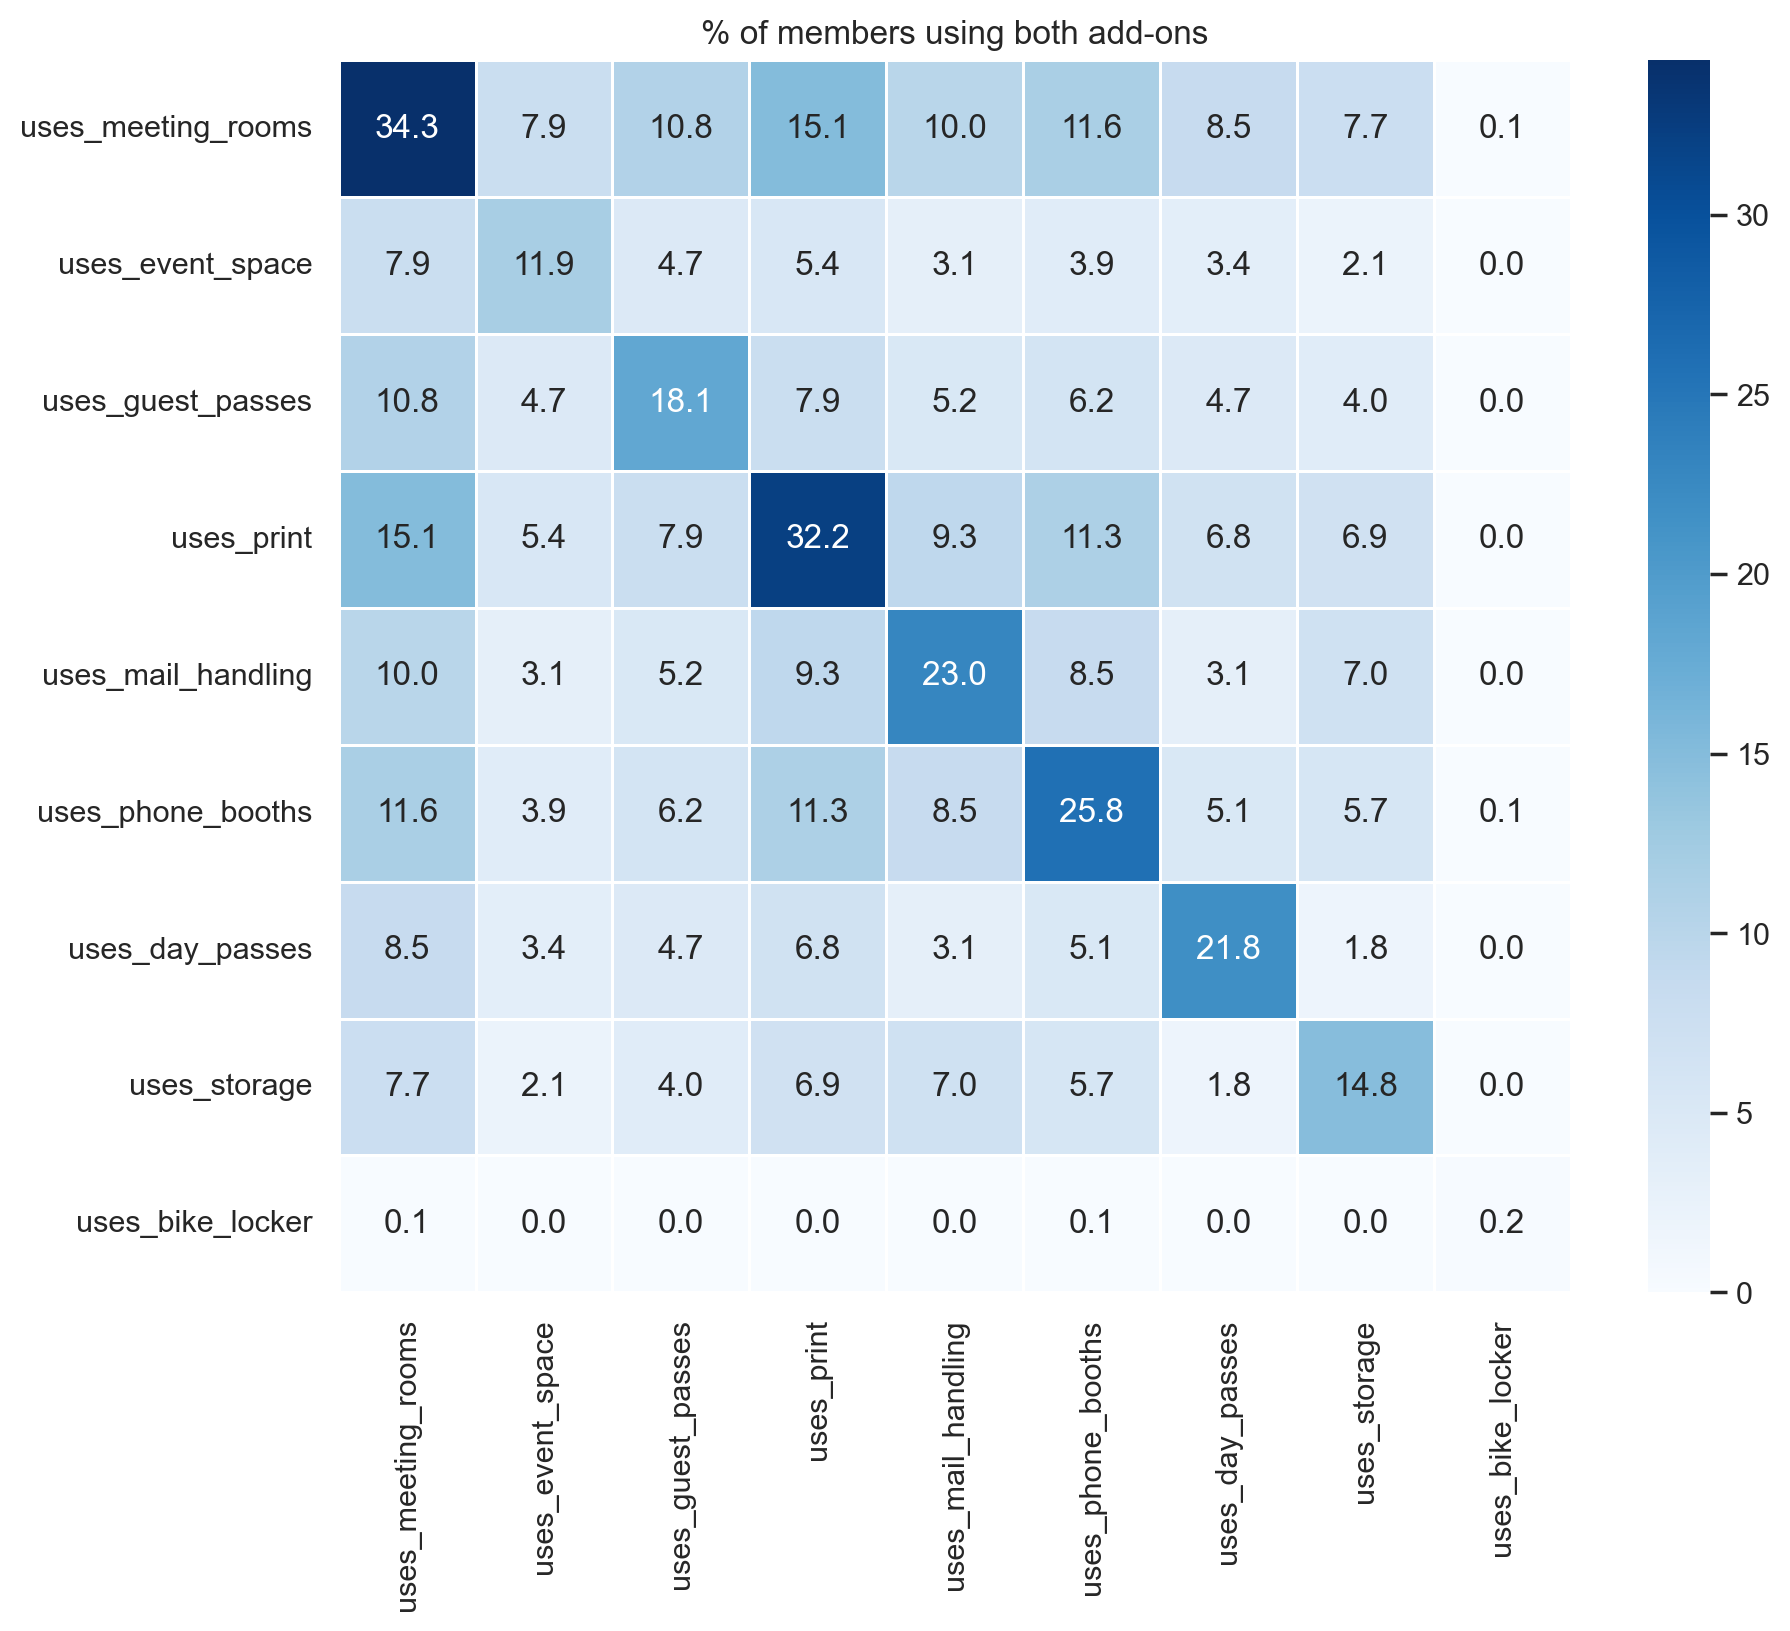

In [52]:
# Co-usage matrix: % of ALL members that use both add-ons (the diagonal is the adoption of each add-on)
co_use = pd.DataFrame(index=addon_cols, columns=addon_cols, dtype=float)
for a in addon_cols:
    for b in addon_cols:
        co_use.loc[a, b] = ((df_clean[a] == 1) & (df_clean[b] == 1)).mean() * 100

plt.figure(figsize=(10, 8))
sns.heatmap(co_use.round(1), annot=True, fmt=".1f", cmap="Blues", square=True, linewidths=.5)
plt.title("% of members using both add-ons")
plt.show()

**Reading the chart:** the diagonal repeats the adoption rate of each add-on, and the other cells show the % of all members who use both add-ons.

- **The most common combination is meeting rooms + print (15.1%),** followed by meeting rooms + phone booths (11.6%), print + phone booths (11.3%), meeting rooms + guest passes (10.8%) and meeting rooms + mail handling (10.0%). The most frequent pairs involve the most popular add-ons, and meeting rooms appear in most of them.
- **Co-usage is mostly higher than expected by chance.** For example, if the two add-ons were independent, we would expect about 11% of members to use both meeting rooms and print (34.3% x 32.2%), but we observe 15.1%. Event space + guest passes is also about twice what chance would give (4.7% vs 2.2%). This suggests that members who use one add-on tend to use more of them.
- **Day passes combine less with storage and mail handling** (1.8% and 3.1%, below the ~3.2% and ~5.0% expected by chance). Day-pass users seem to be members who do not need to leave belongings or receive mail in the space.
- **The bike locker is almost never combined with anything** (0.0-0.1%), as expected from its 0.2% adoption.
- Because popular add-ons overlap more just by being popular, we confirm these patterns with the correlation matrix below.

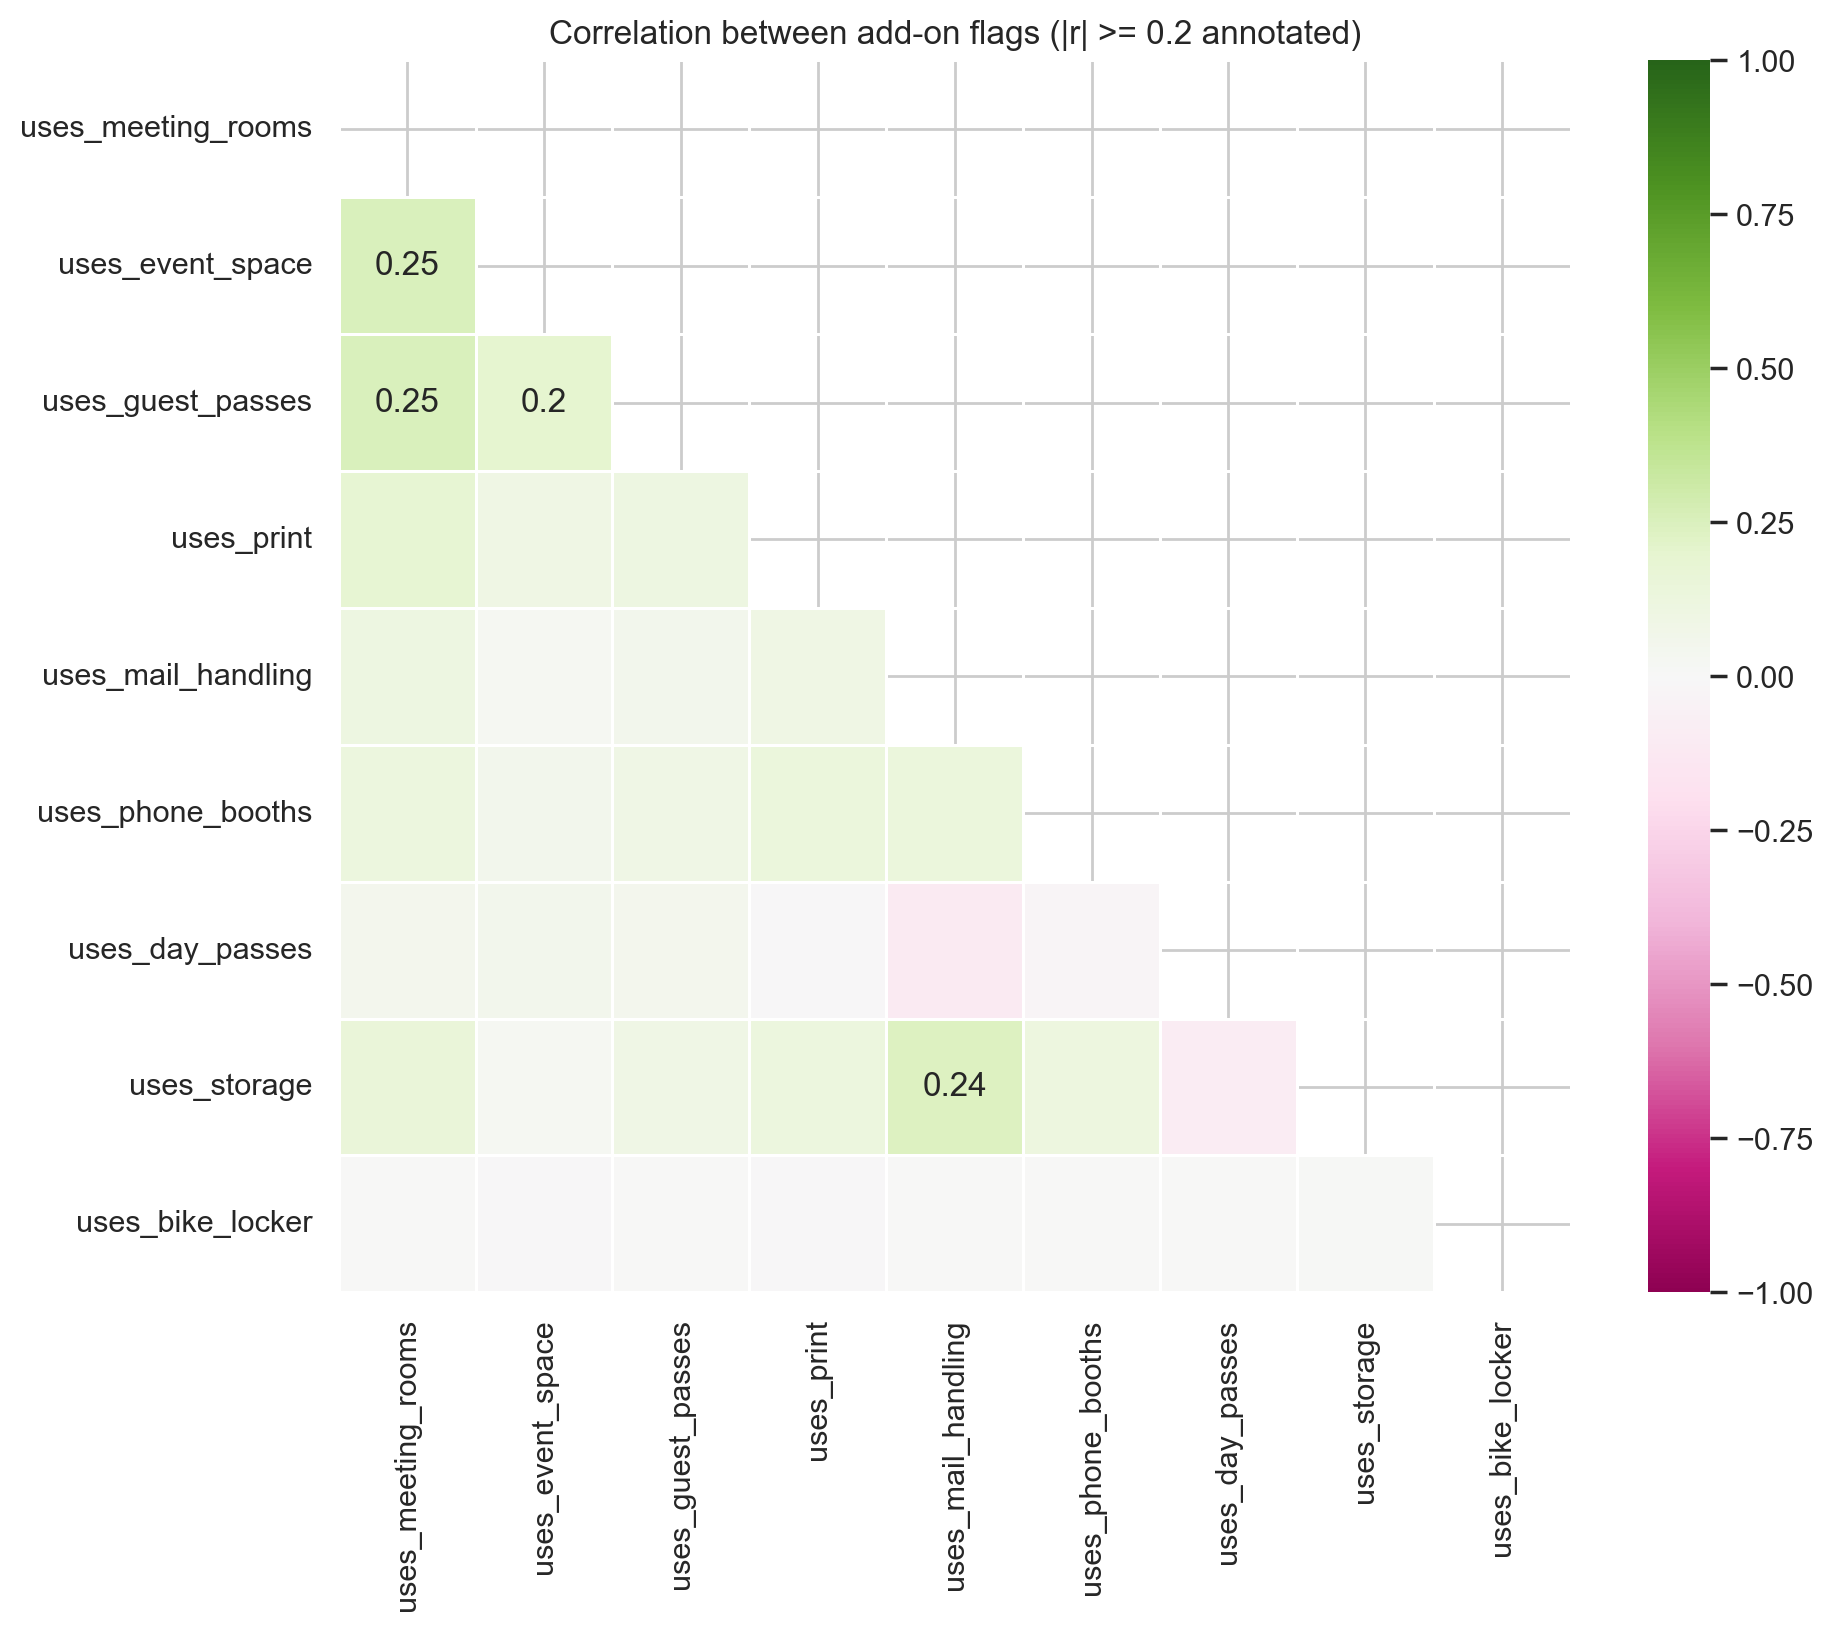

In [53]:
# Correlation between the 0/1 flags (Pearson on binary variables = phi coefficient)
corr_addons = df_clean[addon_cols].corr().round(2)

# show only the lower triangle (the matrix is symmetric) and annotate only the stronger values
mask = np.triu(np.ones_like(corr_addons, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr_addons, mask=mask, center=0, cmap="PiYG", vmin=-1, vmax=1,
            annot=np.where(np.abs(corr_addons) >= 0.2, corr_addons.values, ""),
            fmt="s", square=True, linewidths=.5)
plt.title("Correlation between add-on flags (|r| >= 0.2 annotated)")
plt.show()

**Reading the chart:** correlation between the 0/1 flags (only values with |r| >= 0.2 are written). Unlike the co-usage matrix, it shows if two add-ons go together **more than chance**.

- **All correlations are weak (the highest is 0.25).** Add-ons are mostly independent of each other, so there is no strong "bundle" of services and no add-on is redundant with another.
- **Meeting rooms, event space and guest passes go together** (meeting rooms + event space 0.25, meeting rooms + guest passes 0.25, event space + guest passes 0.20). They are the services related to **hosting meetings, events and visitors**.
- **Storage and mail handling go together** (0.24). They are services for members who **keep a base in the space**.
- **Day passes have a slightly negative relation with mail handling and storage** (light pink cells, close to zero). This is consistent with the co-usage matrix: occasional users do not need a mailbox or storage.
- **The bike locker is not related to any add-on** (correlation close to 0), as expected from its 0.2% adoption.
- **For segmentation:** the weak correlations suggest that each add-on gives some separate information, but two small families appear (hosting and meetings vs. mail and storage). A count of add-ons (`n_addons`) summarises how much of the service a member uses.

### Meeting-room and event-space hours

**What we do in this step:** we plot the distribution of the hours of use and compute the share of members who never used each space. We expect most members at zero and a long tail of heavy users.

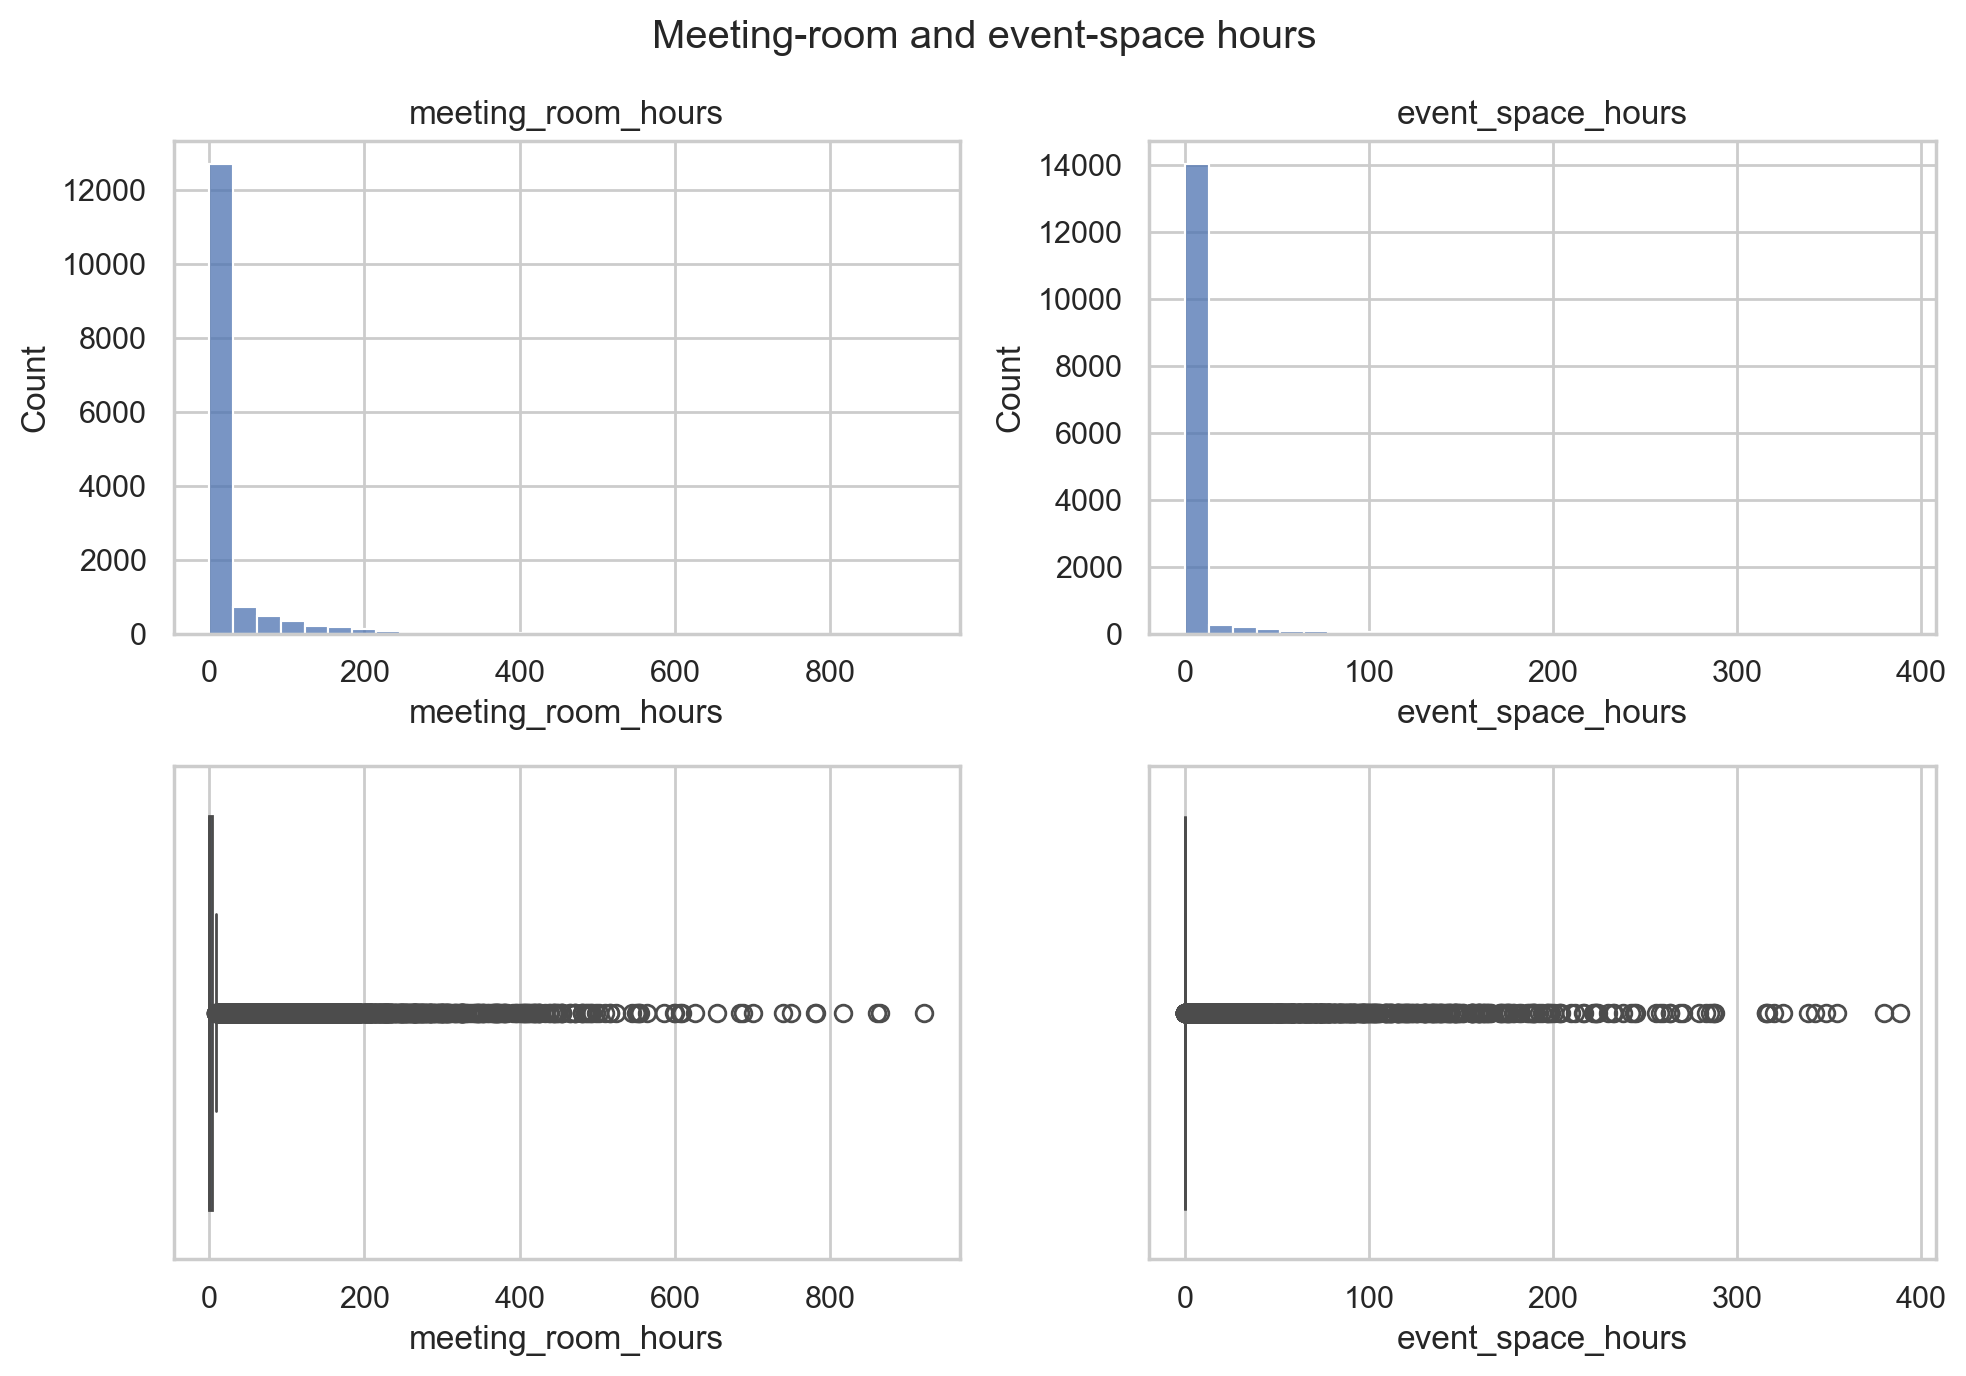

Share of members with zero hours:
meeting_room_hours    0.684
event_space_hours     0.886
dtype: float64


In [54]:
# Histogram and box plot of the hours of use of the rooms
hours_features = ["meeting_room_hours", "event_space_hours"]
plot_hist_box(df_clean, hours_features, "Meeting-room and event-space hours")

# share of members who never used each space
print("Share of members with zero hours:")
print((df_clean[hours_features] == 0).mean().round(3))

## falta conclusão

### Overview numbers (KPIs)

**What we do in this step:** a few headline numbers that summarise the member base.

In [55]:
# Headline numbers of the member base
kpi = {
    "members": len(df_clean),
    "avg lifetime_value": df_clean["lifetime_value"].mean(),
    "avg weekly visits": df_clean["avg_weekly_visits"].mean(),
    "avg # add-ons": df_clean[addon_cols].sum(axis=1).mean(),
}
pd.Series(kpi).round(2).to_frame("value")

,value
members,15082.00
avg lifetime_value,4165.43
avg weekly visits,1.71
avg # add-ons,1.82


### Main takeaways - add-ons

- *(fill in after running)* most and least adopted add-ons
- *(fill in after running)* pairs of add-ons that are used together (co-usage and correlation)
- *(fill in after running)* share of members with zero meeting-room / event-space hours and how long the tail is
- *(fill in after running)* what this suggests: a small group of heavy room users vs a majority that only uses the desk

## 3. Value

**Goal:** understand how much revenue each member brings, how loyal members are (renewals) and what explains the differences.

**What we analyse in this section:**
1. **Distribution of `lifetime_value` and `n_renewals`.**
2. **What is associated with a higher lifetime value** (correlations and plan tier).
3. **Concentration of value**: how much of the total revenue comes from the top 10% of members.

**Why it matters for segmentation:** value-based segmentation is one of the perspectives required by the project (guidelines, section 2).

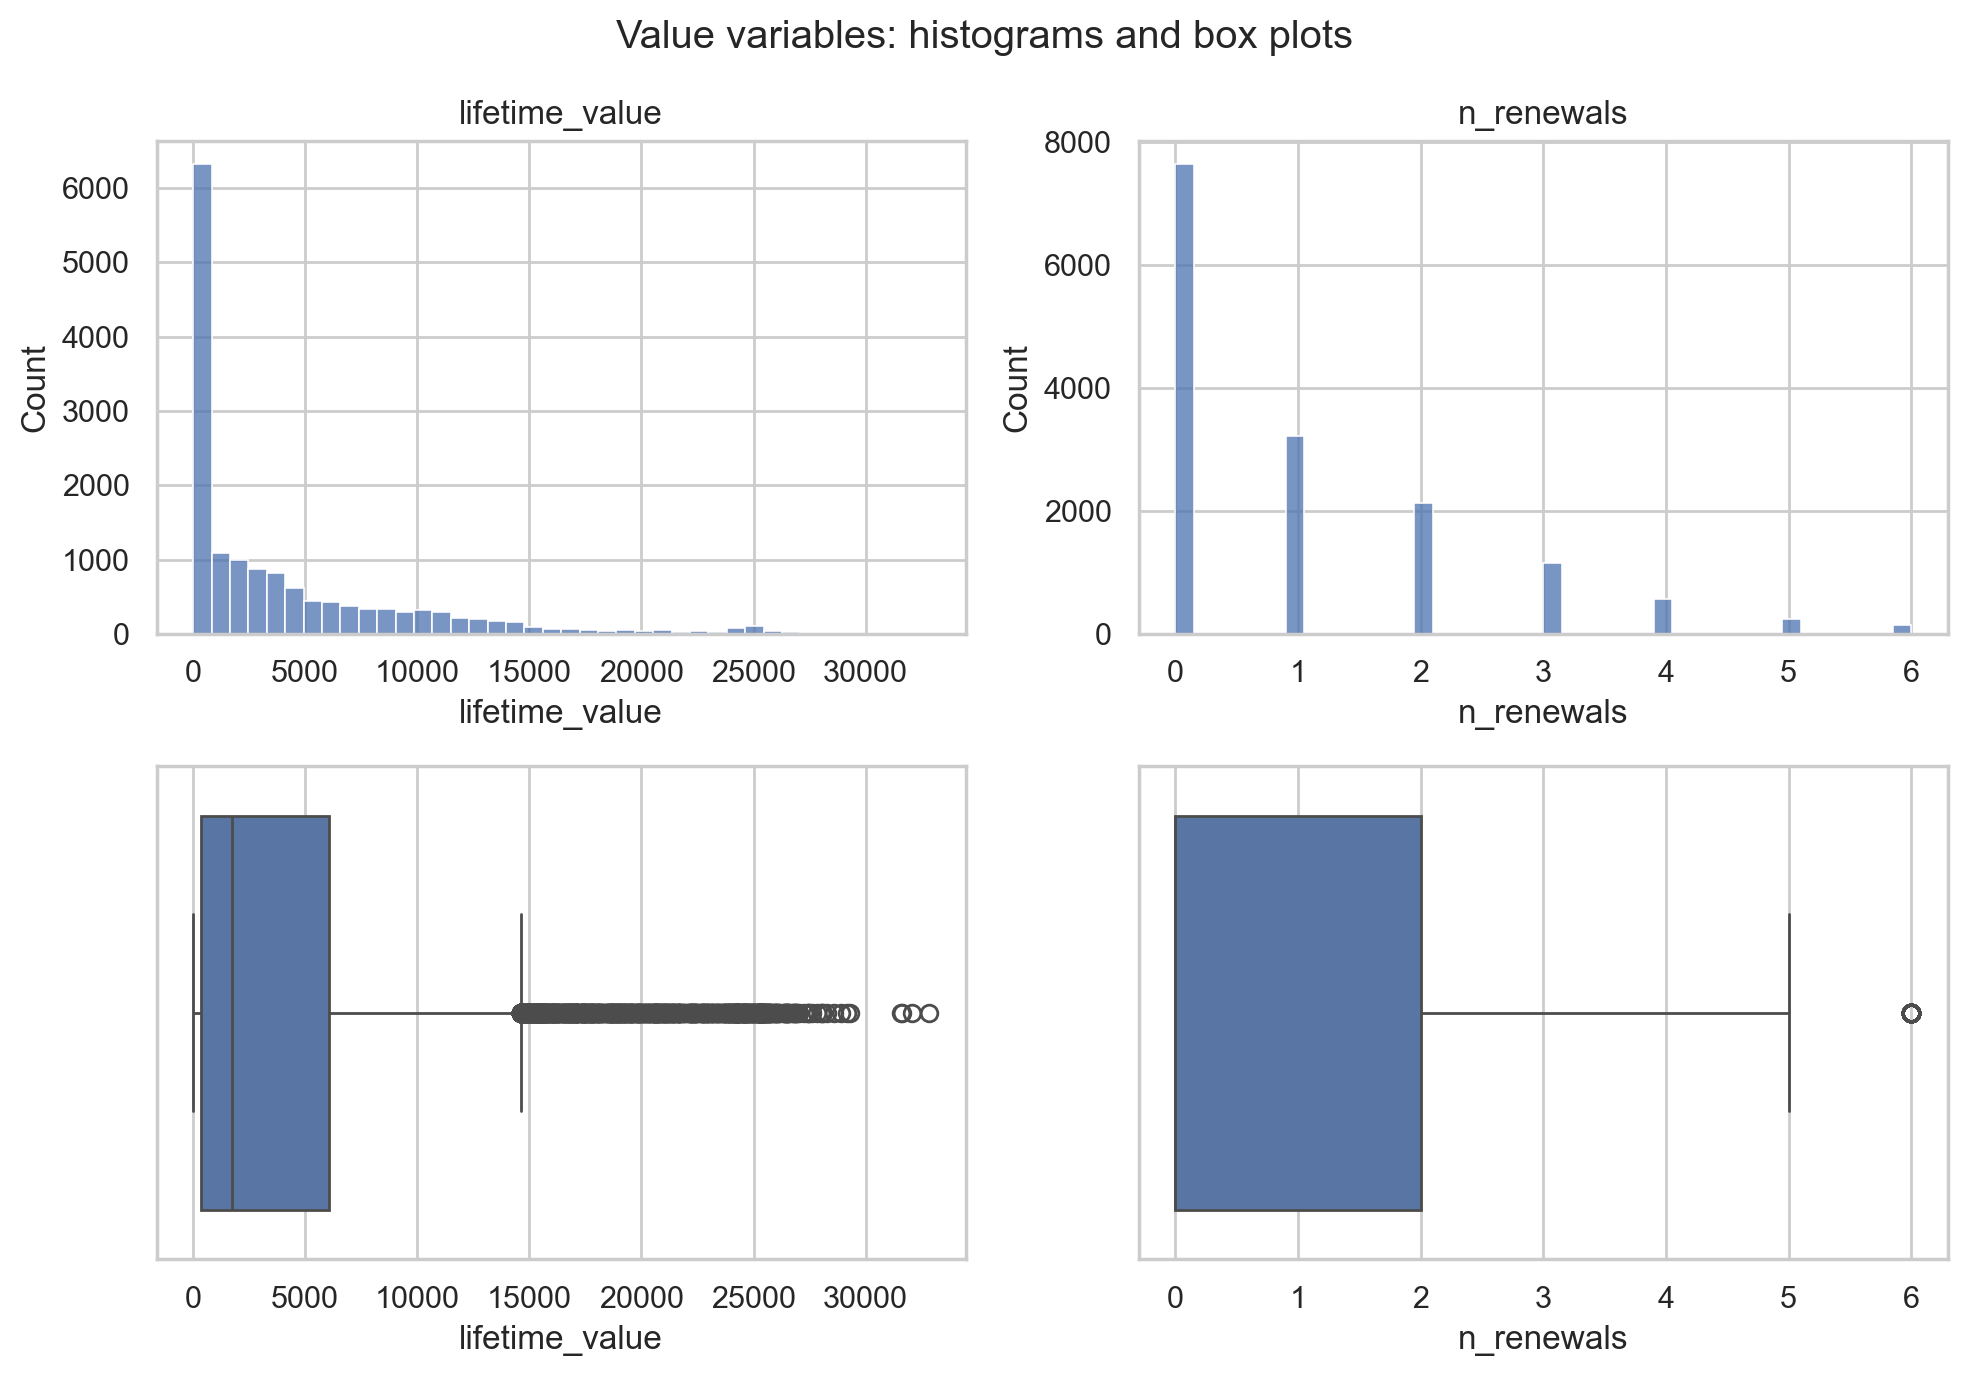

In [56]:
# Histogram and box plot of the revenue and of the number of renewals
plot_hist_box(df_clean, ["lifetime_value", "n_renewals"], "Value variables: histograms and box plots", bins=40)

### Main takeaways - value distributions

- *(fill in after running)* how skewed `lifetime_value` is and what the long tail means
- *(fill in after running)* typical number of renewals

### What is associated with lifetime value?

**What we do in this step:** we compute the correlation of every other metric feature with `lifetime_value`.

> **Caveat:** part of `lifetime_value` was imputed as *plan price x tenure*, so its correlation with plan tier and tenure is partly built in. We read the bars as an upper bound.

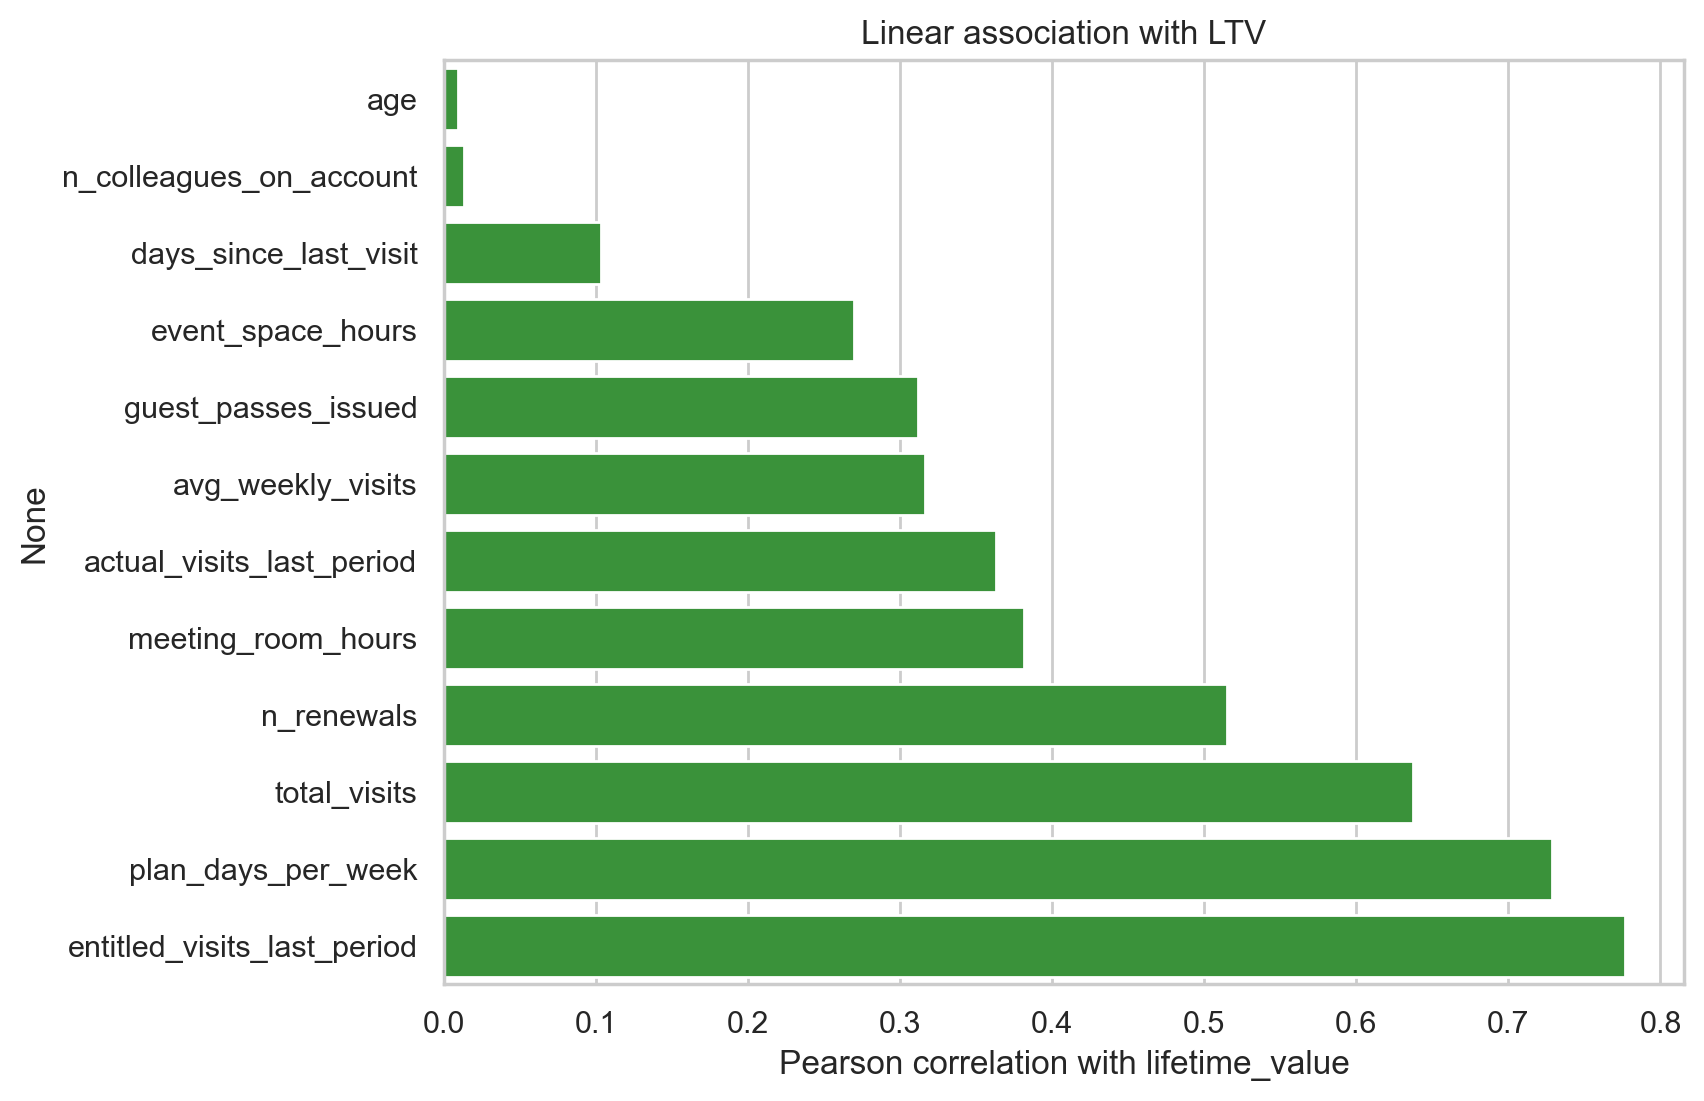

In [57]:
# Pearson correlation of every other metric feature with lifetime_value, sorted
drivers = [c for c in metric_features if c != "lifetime_value"]
corr_ltv = df_clean[drivers + ["lifetime_value"]].corr()["lifetime_value"].drop("lifetime_value").sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=corr_ltv.values, y=corr_ltv.index, ax=ax, color="tab:green")
ax.set_xlabel("Pearson correlation with lifetime_value")
ax.set_title("Linear association with LTV")
plt.show()

## conclusão

### Lifetime value and renewals by plan tier

**What we do in this step:** box plots of `lifetime_value` and `n_renewals` for each plan tier (categorical vs numeric variable, as in lab05), and a table with the mean and median per tier.

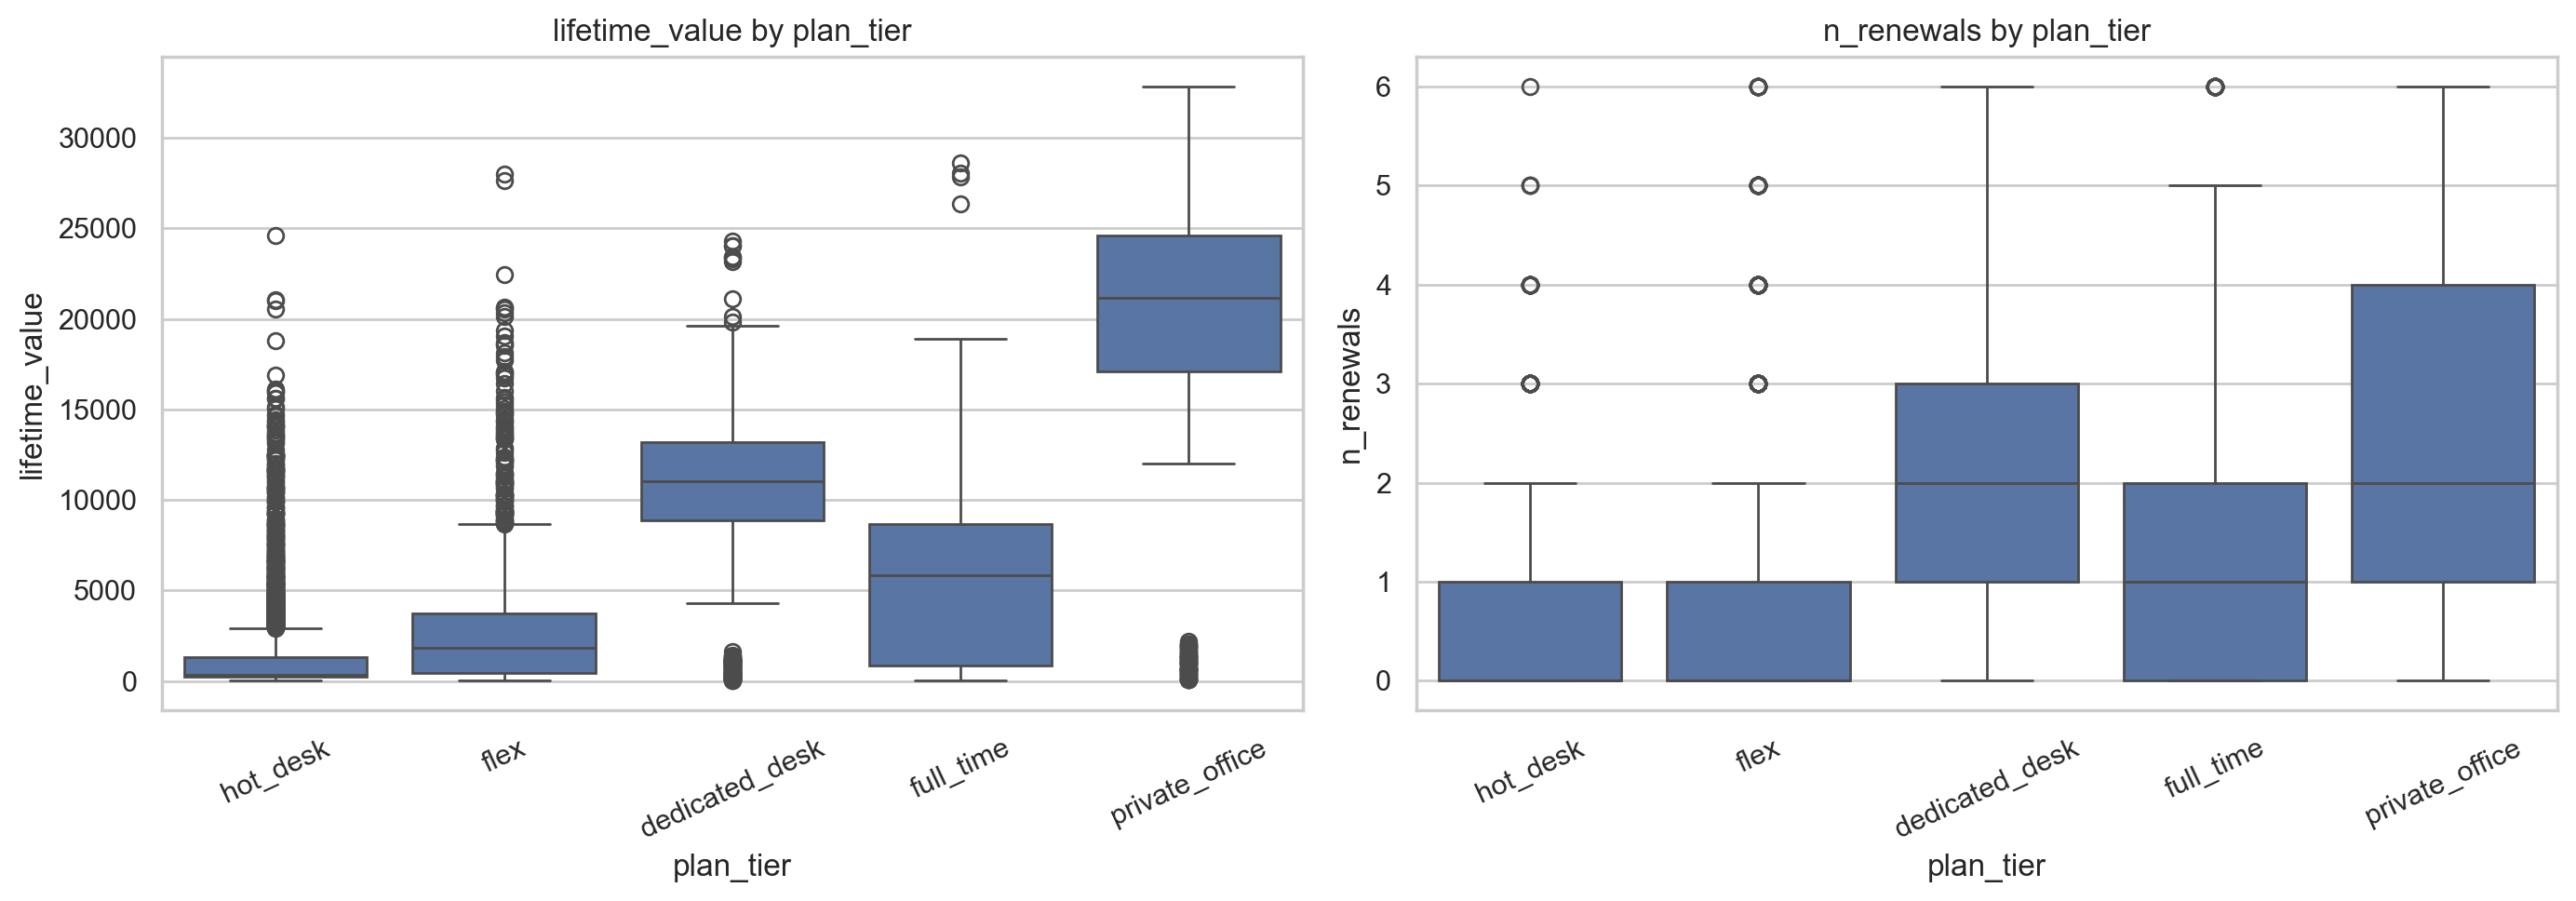

,count,mean,median
plan_tier,,,
hot_desk,5103,1206.5,357.1
flex,5325,2443.0,1825.0
dedicated_desk,1525,10723.3,11045.0
full_time,2433,5669.1,5837.3
private_office,696,19412.3,21161.2


In [58]:
# Tiers in the metadata order (only those that exist in the data)
tier_order = [t for t in TIER_ORDER if t in df_clean["plan_tier"].unique()]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), tight_layout=True)
sns.boxplot(data=df_clean, x="plan_tier", y="lifetime_value", order=tier_order, ax=axes[0])
axes[0].set_title("lifetime_value by plan_tier")
axes[0].tick_params(axis="x", rotation=25)
sns.boxplot(data=df_clean, x="plan_tier", y="n_renewals", order=tier_order, ax=axes[1])
axes[1].set_title("n_renewals by plan_tier")
axes[1].tick_params(axis="x", rotation=25)
plt.show()

# Numbers per tier: members, mean and median LTV
df_clean.groupby("plan_tier")["lifetime_value"].agg(["count", "mean", "median"]).round(1).reindex(tier_order)

### Concentration of value

**What we do in this step:** we sort members by `lifetime_value` and compute the share of the total revenue that comes from the top 10%.

In [59]:
# Share of the total revenue that comes from the top 10% of members
ltv_sorted = df_clean["lifetime_value"].sort_values(ascending=False)
top10 = ltv_sorted.head(int(len(ltv_sorted) * 0.10)).sum() / ltv_sorted.sum()
print(f"Top 10% of members generate {top10:.1%} of total lifetime value")

Top 10% of members generate 41.3% of total lifetime value


### Main takeaways - value

- *(fill in after running)* which variables are most associated with `lifetime_value` (remember the imputation caveat)
- *(fill in after running)* how lifetime value and renewals differ across plan tiers
- *(fill in after running)* share of the revenue that comes from the top 10% of members

## 4. Feature engineering

**Goal:** create new variables that describe behaviour and value better than the original columns, so that clustering can find richer groups.

| Feature | Formula | What it captures |
|---|---|---|
| `tenure_days` | (`membership_end` or extraction date) - `membership_start` | Loyalty |
| `recency_days` | extraction date - `last_badge_swipe` | True recency at the extraction date (used for the R score) |
| `utilization_rate` | actual / entitled visits (last period) | Value obtained from the plan; churn risk |
| `ltv_per_month` | `lifetime_value` / tenure in months | Worth per month, regardless of tenure |
| `ltv_vs_tier` | `ltv_per_month` / median `ltv_per_month` of the tier | Spend above the plan price (add-ons) |
| `n_addons` | sum of `uses_*` | How much of the service the member uses |
| `hours_per_visit` | (meeting + event hours) / `total_visits` | Office/events use vs just a desk |
| `is_active` | `membership_end` is missing | Active vs churned |
| `plan_tier_ord` | hot_desk=1 ... private_office=5 (metadata order) | Plan tier as a numeric scale (see the note below) |
| `r_score`, `f_score`, `m_score`, `rfm_score` | quantiles of recency, frequency and LTV | Value-based segmentation (RFM) |

**Missing values created by the ratios** (for example, 0 entitled visits) are *not* MCAR, MAR or MNAR: they are *undefined by construction* (division by zero). We leave them as NaN instead of imputing them.

In [60]:
# Create all engineered features with the function defined in the Functions section
df_fe = engineer_features(df_clean, EXTRACTION_DATE)

engineered_features = ["tenure_days", "recency_days", "utilization_rate", "ltv_per_month", "ltv_vs_tier",
                       "n_addons", "hours_per_visit", "is_active", "plan_tier_ord",
                       "r_score", "f_score", "m_score", "rfm_score"]

# sanity checks: a tenure <= 0 would be a data problem, and every tier must have been mapped to a number
print("Members with tenure_days <= 0:", (df_fe["tenure_days"] <= 0).sum())
print("plan_tier values not mapped:", df_fe.loc[df_fe["plan_tier_ord"].isna(), "plan_tier"].unique())

# summary statistics of the new features
df_fe[engineered_features].describe().round(2).T

Members with tenure_days <= 0: 0
plan_tier values not mapped: []


,count,mean,std,min,25%,50%,75%,max
tenure_days,15082.0,373.50,338.45,2.00,65.00,281.00,635.00,1095.00
recency_days,15082.0,320.30,287.01,0.00,77.00,240.00,506.00,1095.00
utilization_rate,15082.0,0.52,0.31,0.00,0.24,0.52,0.80,1.00
ltv_per_month,15082.0,264.56,159.90,93.37,150.07,204.85,314.91,2311.55
ltv_vs_tier,15082.0,1.13,0.55,0.69,0.93,1.00,1.09,9.95
n_addons,15082.0,1.82,1.50,0.00,1.00,1.00,3.00,8.00
hours_per_visit,14976.0,0.32,1.10,0.00,0.00,0.00,0.12,26.05
is_active,15082.0,0.26,0.44,0.00,0.00,0.00,1.00,1.00
plan_tier_ord,15082.0,2.22,1.20,1.00,1.00,2.00,3.00,5.00
r_score,15082.0,3.00,1.41,1.00,2.00,3.00,4.00,5.00


### Quality check of the engineered features

**What we do in this step:** we count the missing values and infinities created by the ratios and look at the range of each feature. Extreme values should be discussed with the outlier analysis.

In [61]:
# NaN = undefined ratio, inf = an unprotected division (should be 0), min/max = range of each feature
check = pd.DataFrame({
    "n_nan": df_fe[engineered_features].isna().sum(),
    "n_inf": np.isinf(df_fe[engineered_features]).sum(),
    "min": df_fe[engineered_features].min(),
    "max": df_fe[engineered_features].max(),
})
check

,n_nan,n_inf,min,max
tenure_days,0,0,2.000000,1095.000000
recency_days,0,0,0.000000,1095.000000
utilization_rate,0,0,0.000000,1.000000
ltv_per_month,0,0,93.374700,2311.553472
ltv_vs_tier,0,0,0.693953,9.952927
n_addons,0,0,0.000000,8.000000
hours_per_visit,106,0,0.000000,26.051852
is_active,0,0,0.000000,1.000000
plan_tier_ord,0,0,1.000000,5.000000
r_score,0,0,1.000000,5.000000


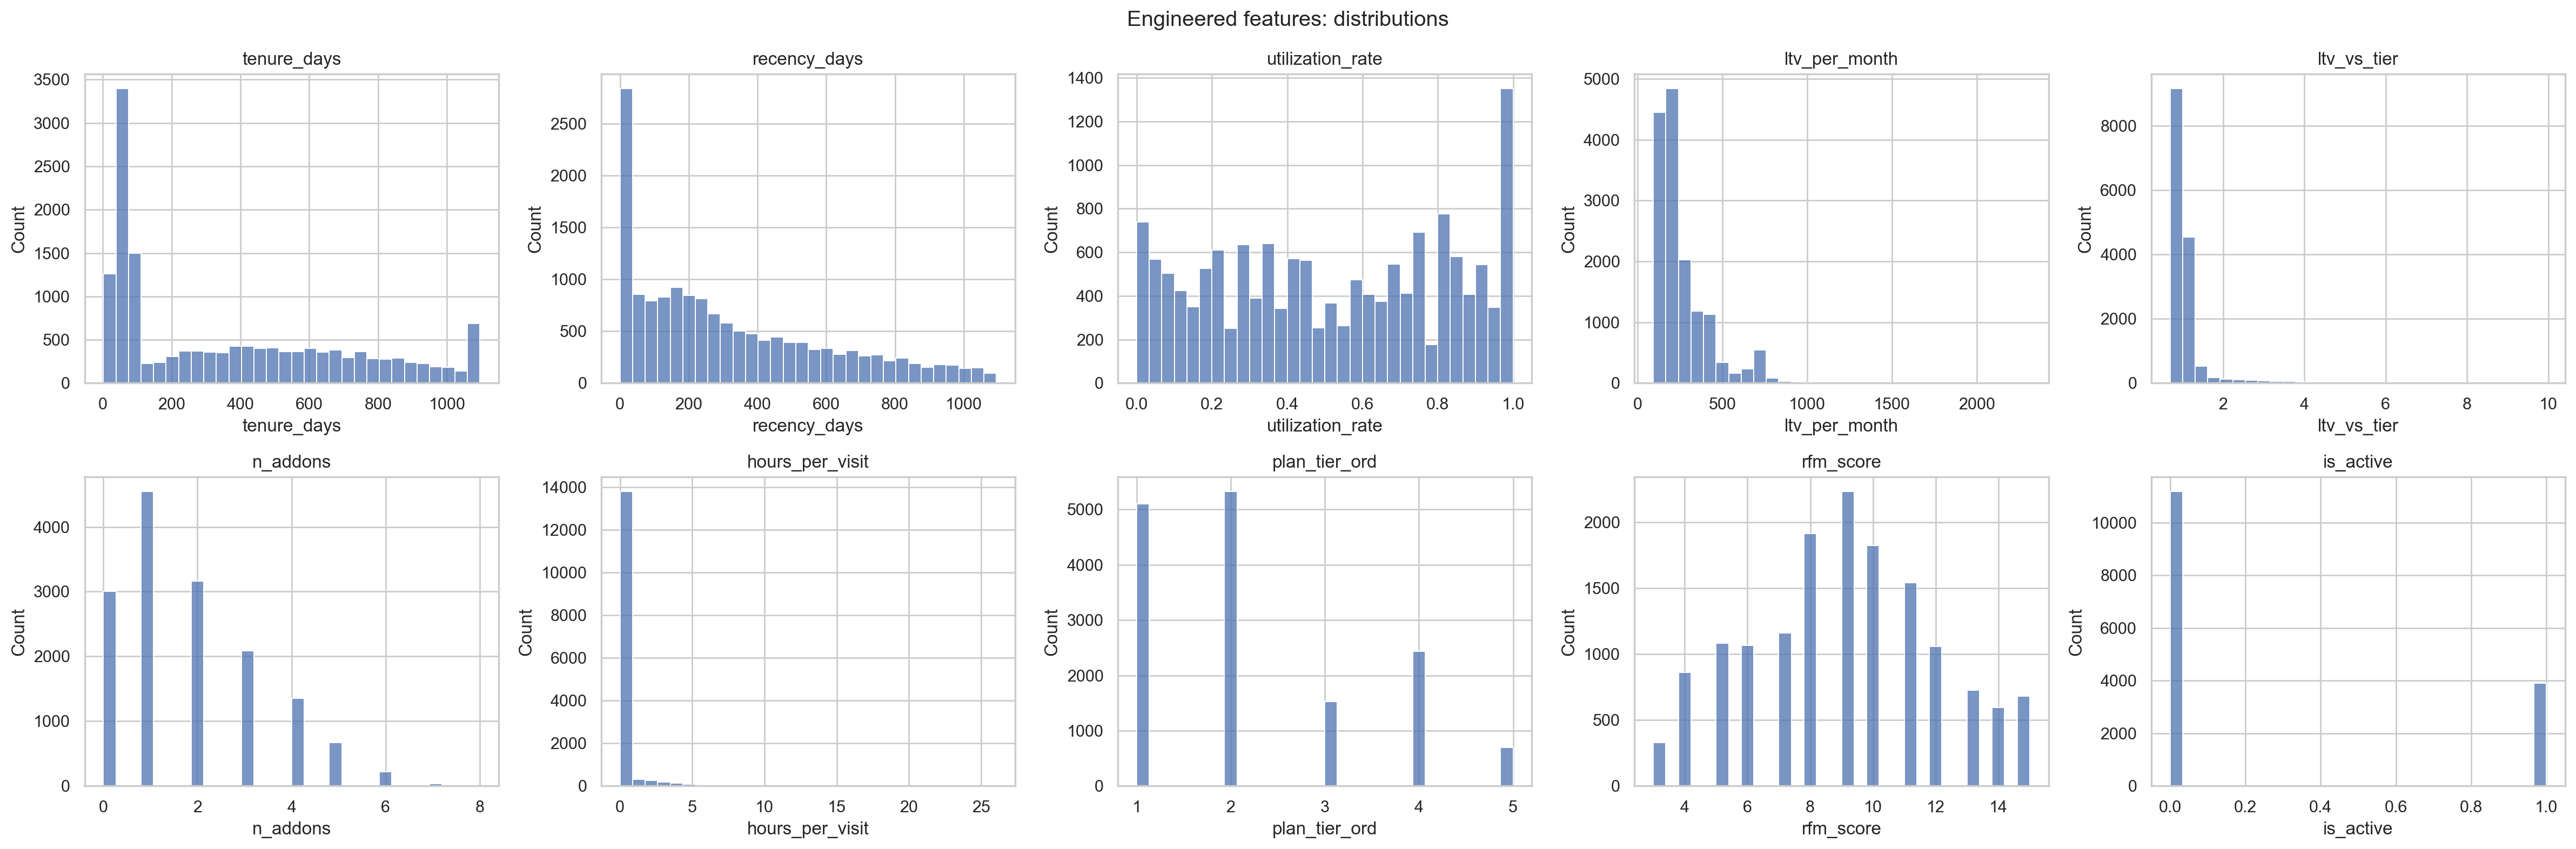

In [62]:
# Distribution of the main engineered features (inf and NaN are removed only for plotting)
plot_features = ["tenure_days", "recency_days", "utilization_rate", "ltv_per_month", "ltv_vs_tier",
                 "n_addons", "hours_per_visit", "plan_tier_ord", "rfm_score", "is_active"]

fig, axes = plt.subplots(2, 5, figsize=(24, 8), tight_layout=True)
for ax, feat in zip(axes.flatten(), plot_features):
    sns.histplot(df_fe[feat].replace([np.inf, -np.inf], np.nan).dropna(), bins=30, ax=ax)
    ax.set_title(feat)
fig.suptitle("Engineered features: distributions")
plt.show()

### Main takeaways - engineered features

- *(fill in after running)* which engineered features are skewed and may need a transformation
- *(fill in after running)* which ones show more than one peak (a sign of different groups)
- *(fill in after running)* extreme values or undefined values (NaN) that need attention

### Two checks on the features that depend on the cleaning

1. **Imputed LTV:** members whose `ltv_vs_tier` is almost exactly 1 are probably the imputed ones (plan price x months).
2. **Tier order:** is the metadata order (`plan_tier_ord`) also the price order?

In [63]:
# 1. Share of members whose revenue per month equals the tier's median almost exactly (probably imputed values)
share_exact = (df_fe["ltv_vs_tier"].sub(1).abs() < 0.005).mean()
print(f"Members with ltv_vs_tier within 0.5% of 1: {share_exact:.1%} (expected ~18.5% imputed in the cleaning)")

# 2. Median revenue per month of each tier (~ the monthly price), in the metadata order
price_by_tier = df_fe.groupby("plan_tier")["ltv_per_month"].median().round(1).reindex(tier_order)
print("Median ltv_per_month by tier (metadata order):")
print(price_by_tier.to_string())
print("Same order as the price?", price_by_tier.is_monotonic_increasing)

Members with ltv_vs_tier within 0.5% of 1: 20.7% (expected ~18.5% imputed in the cleaning)
Median ltv_per_month by tier (metadata order):
plan_tier
hot_desk          132.6
flex              204.8
dedicated_desk    407.2
full_time         312.9
private_office    702.7
Same order as the price? False


> If `dedicated_desk` is more expensive than `full_time`, then `plan_tier_ord` (metadata order) is **not** a price scale.
> The group has to decide which one to use for clustering (a price-based rank is the safer choice for distance-based methods).

## 5. First look at possible groups

**Goal:** check, with plots only (no clustering yet), whether the engineered features suggest natural groups of members.

**What we do in this section:**
1. **Pair plots** of the main engineered features, coloured by `plan_tier` and by active/churned. Separated "clouds" of points suggest different groups.
2. **Correlation between the engineered features.** Very high values mean redundancy, so some features could be dropped before clustering.

In [64]:
# Features shown in the pair plots (few, otherwise the figure is unreadable)
pair_features = ["tenure_days", "recency_days", "utilization_rate", "ltv_vs_tier", "n_addons", "hours_per_visit"]

# Remove inf/NaN (pair plots cannot draw them) and add a readable label for active/churned
df_pair = df_fe[pair_features + ["plan_tier", "is_active"]].replace([np.inf, -np.inf], np.nan).dropna()
df_pair["status"] = df_pair["is_active"].map({1: "active", 0: "churned"})

# A 2000-row random sample keeps the plot fast; this is only a visual check
sample = df_pair.sample(min(2000, len(df_pair)), random_state=42)

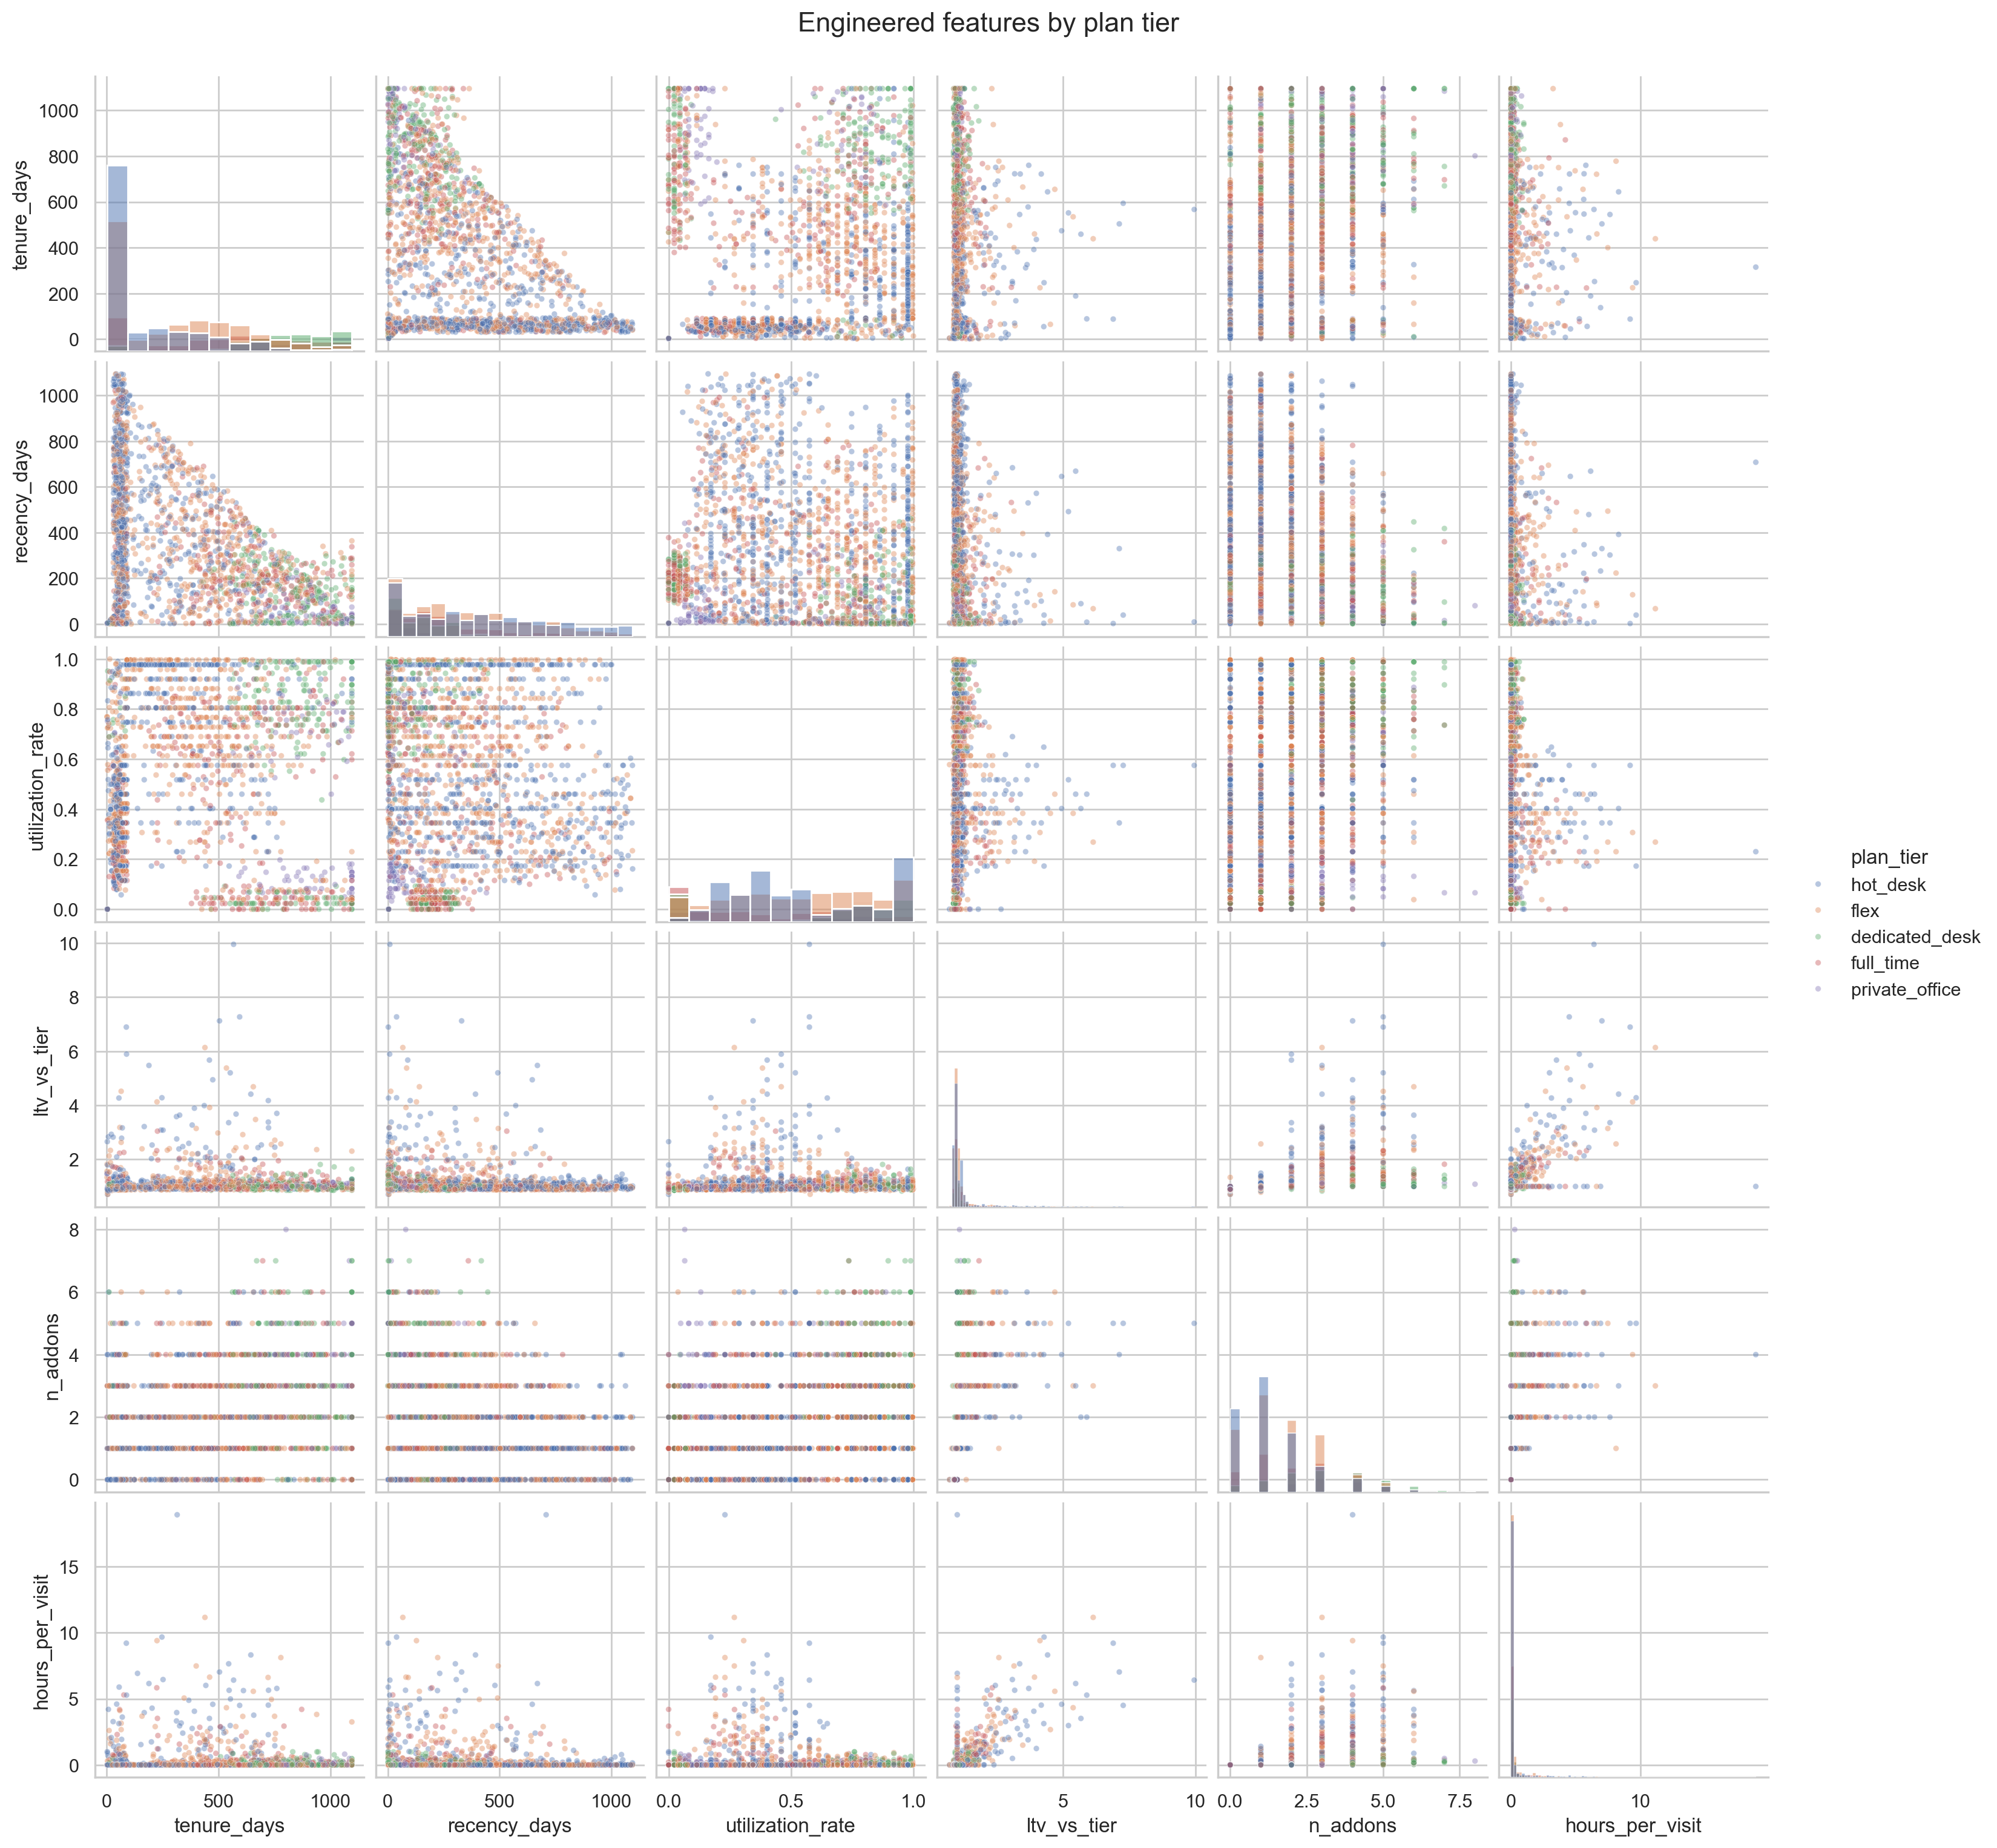

In [65]:
# Pair plot coloured by plan tier: do the tiers separate in any feature?
g = sns.pairplot(sample, vars=pair_features, hue="plan_tier", hue_order=tier_order,
                 diag_kind="hist", plot_kws={"alpha": 0.4, "s": 12})
g.figure.suptitle("Engineered features by plan tier", y=1.02, fontsize=16)
plt.show()

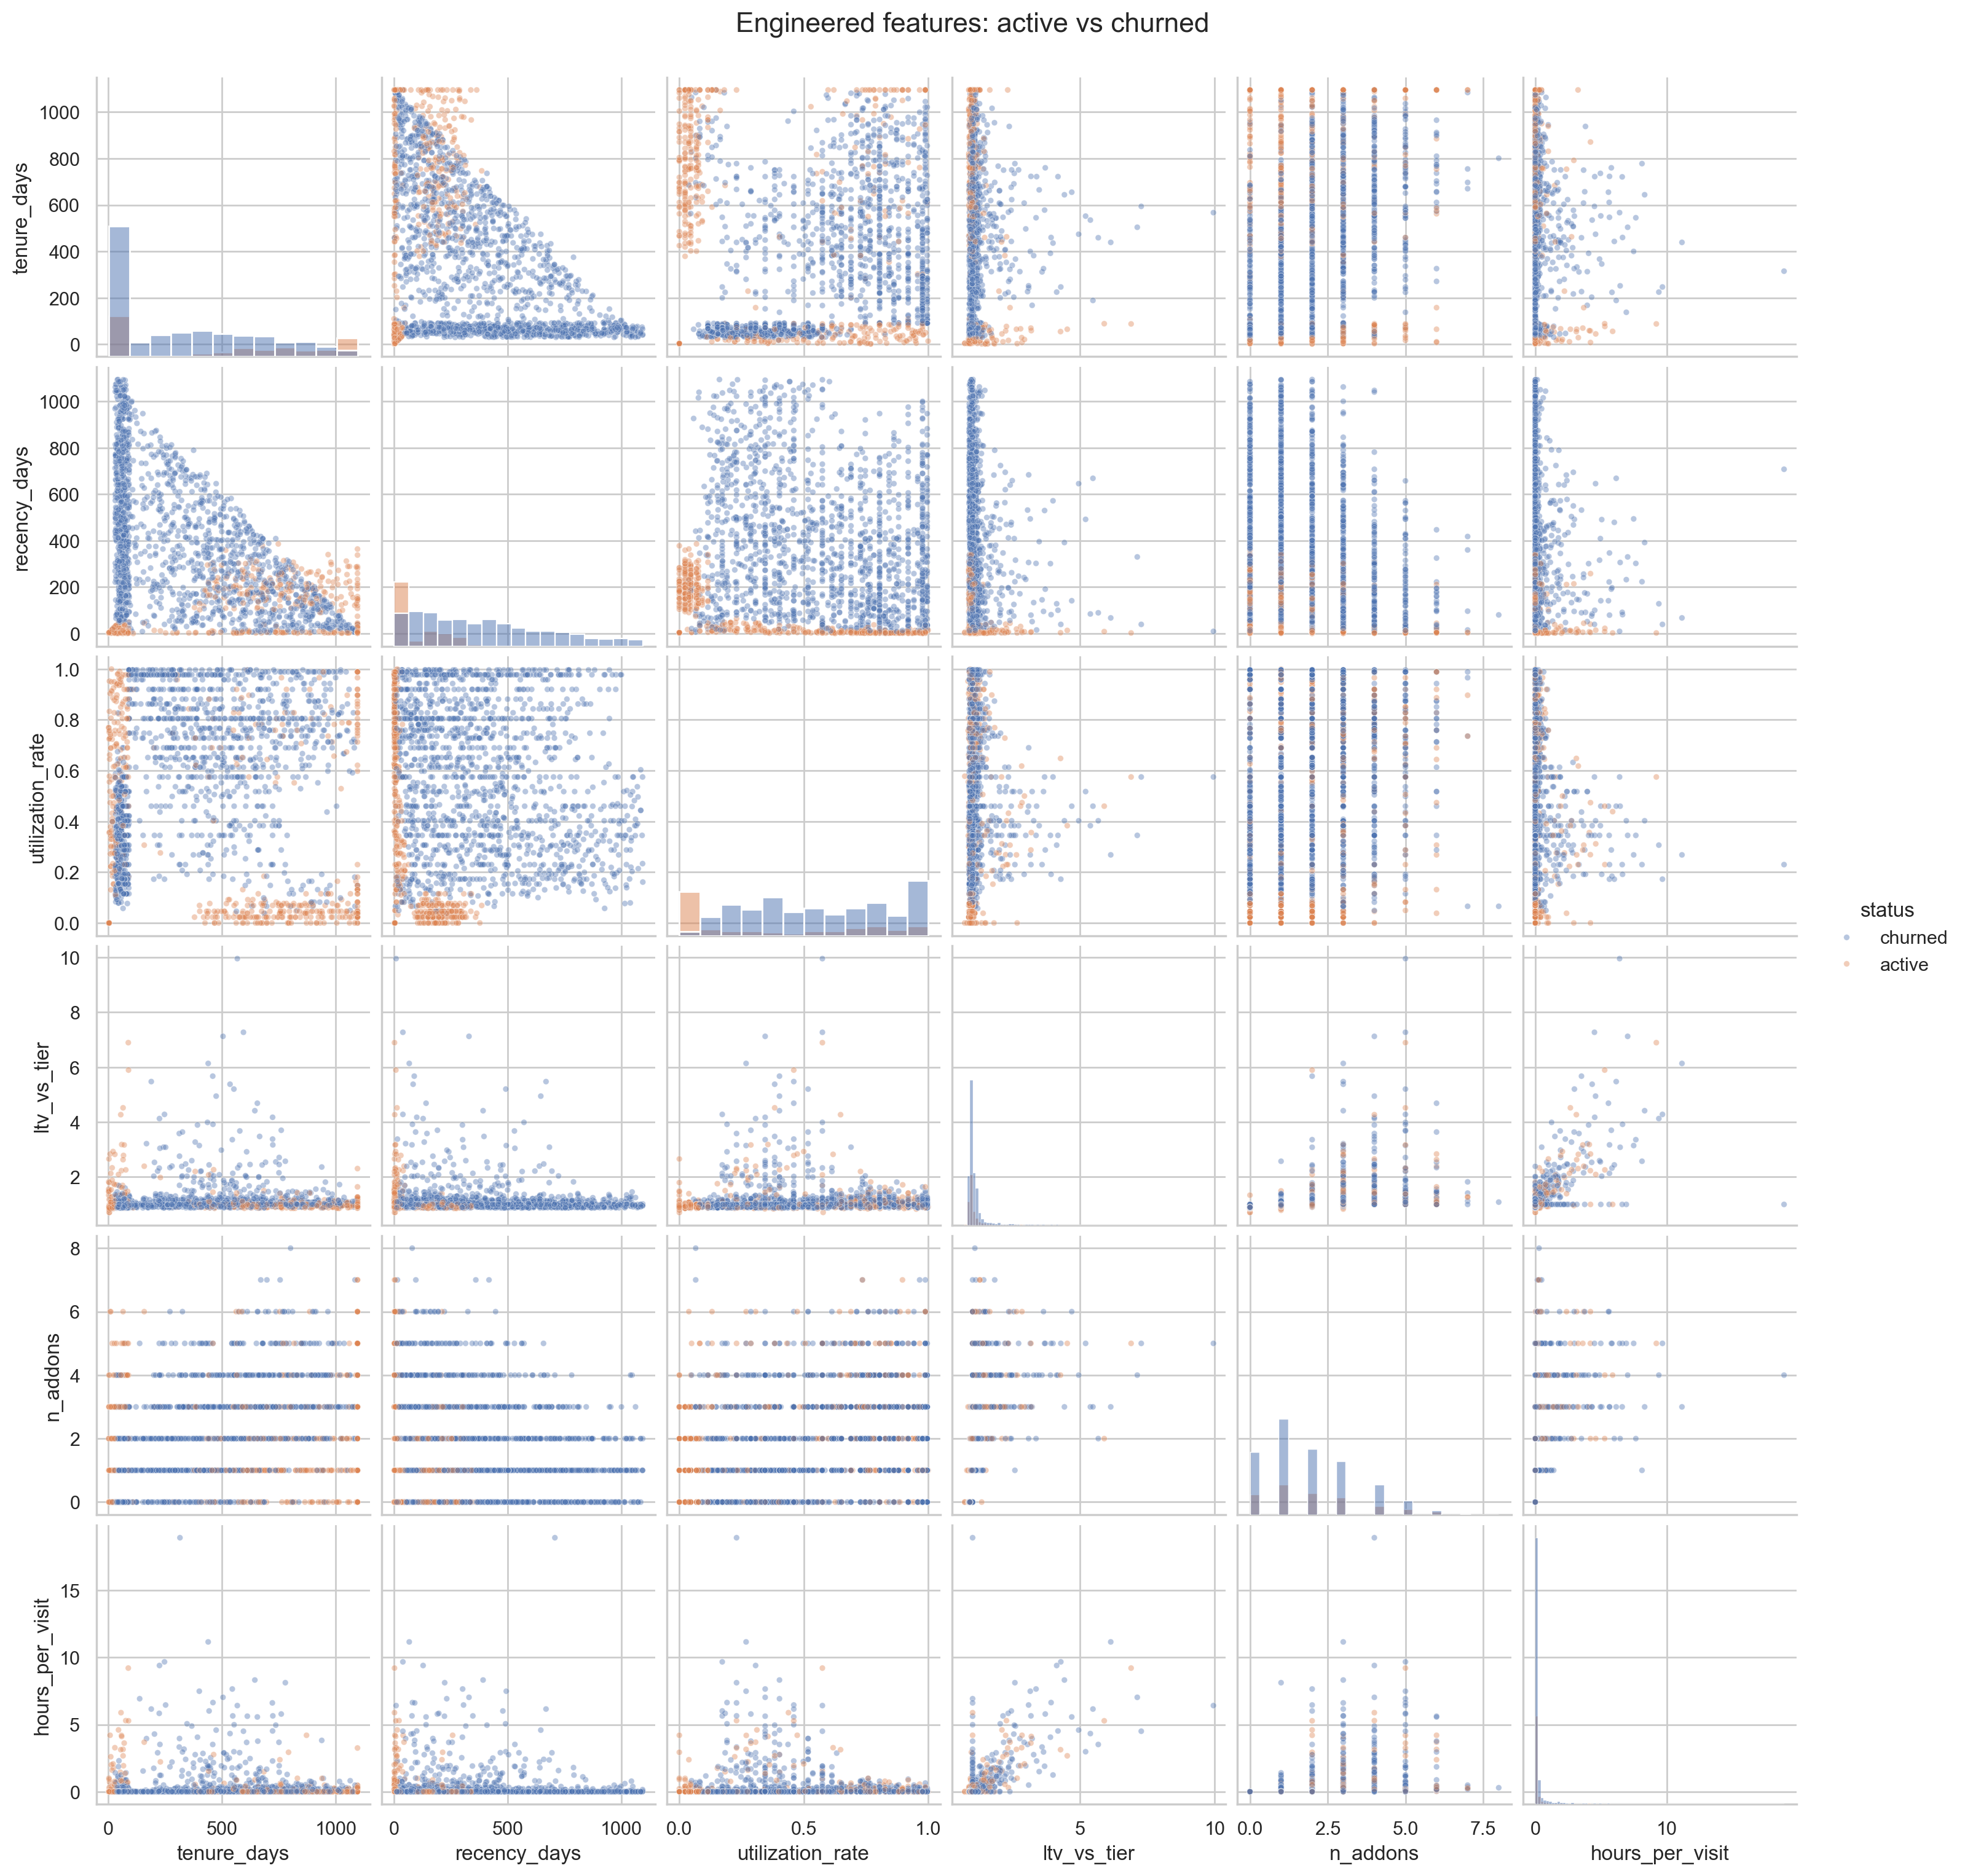

In [66]:
# Pair plot coloured by status: do active and churned members behave differently?
g = sns.pairplot(sample, vars=pair_features, hue="status",
                 diag_kind="hist", plot_kws={"alpha": 0.4, "s": 12})
g.figure.suptitle("Engineered features: active vs churned", y=1.02, fontsize=16)
plt.show()

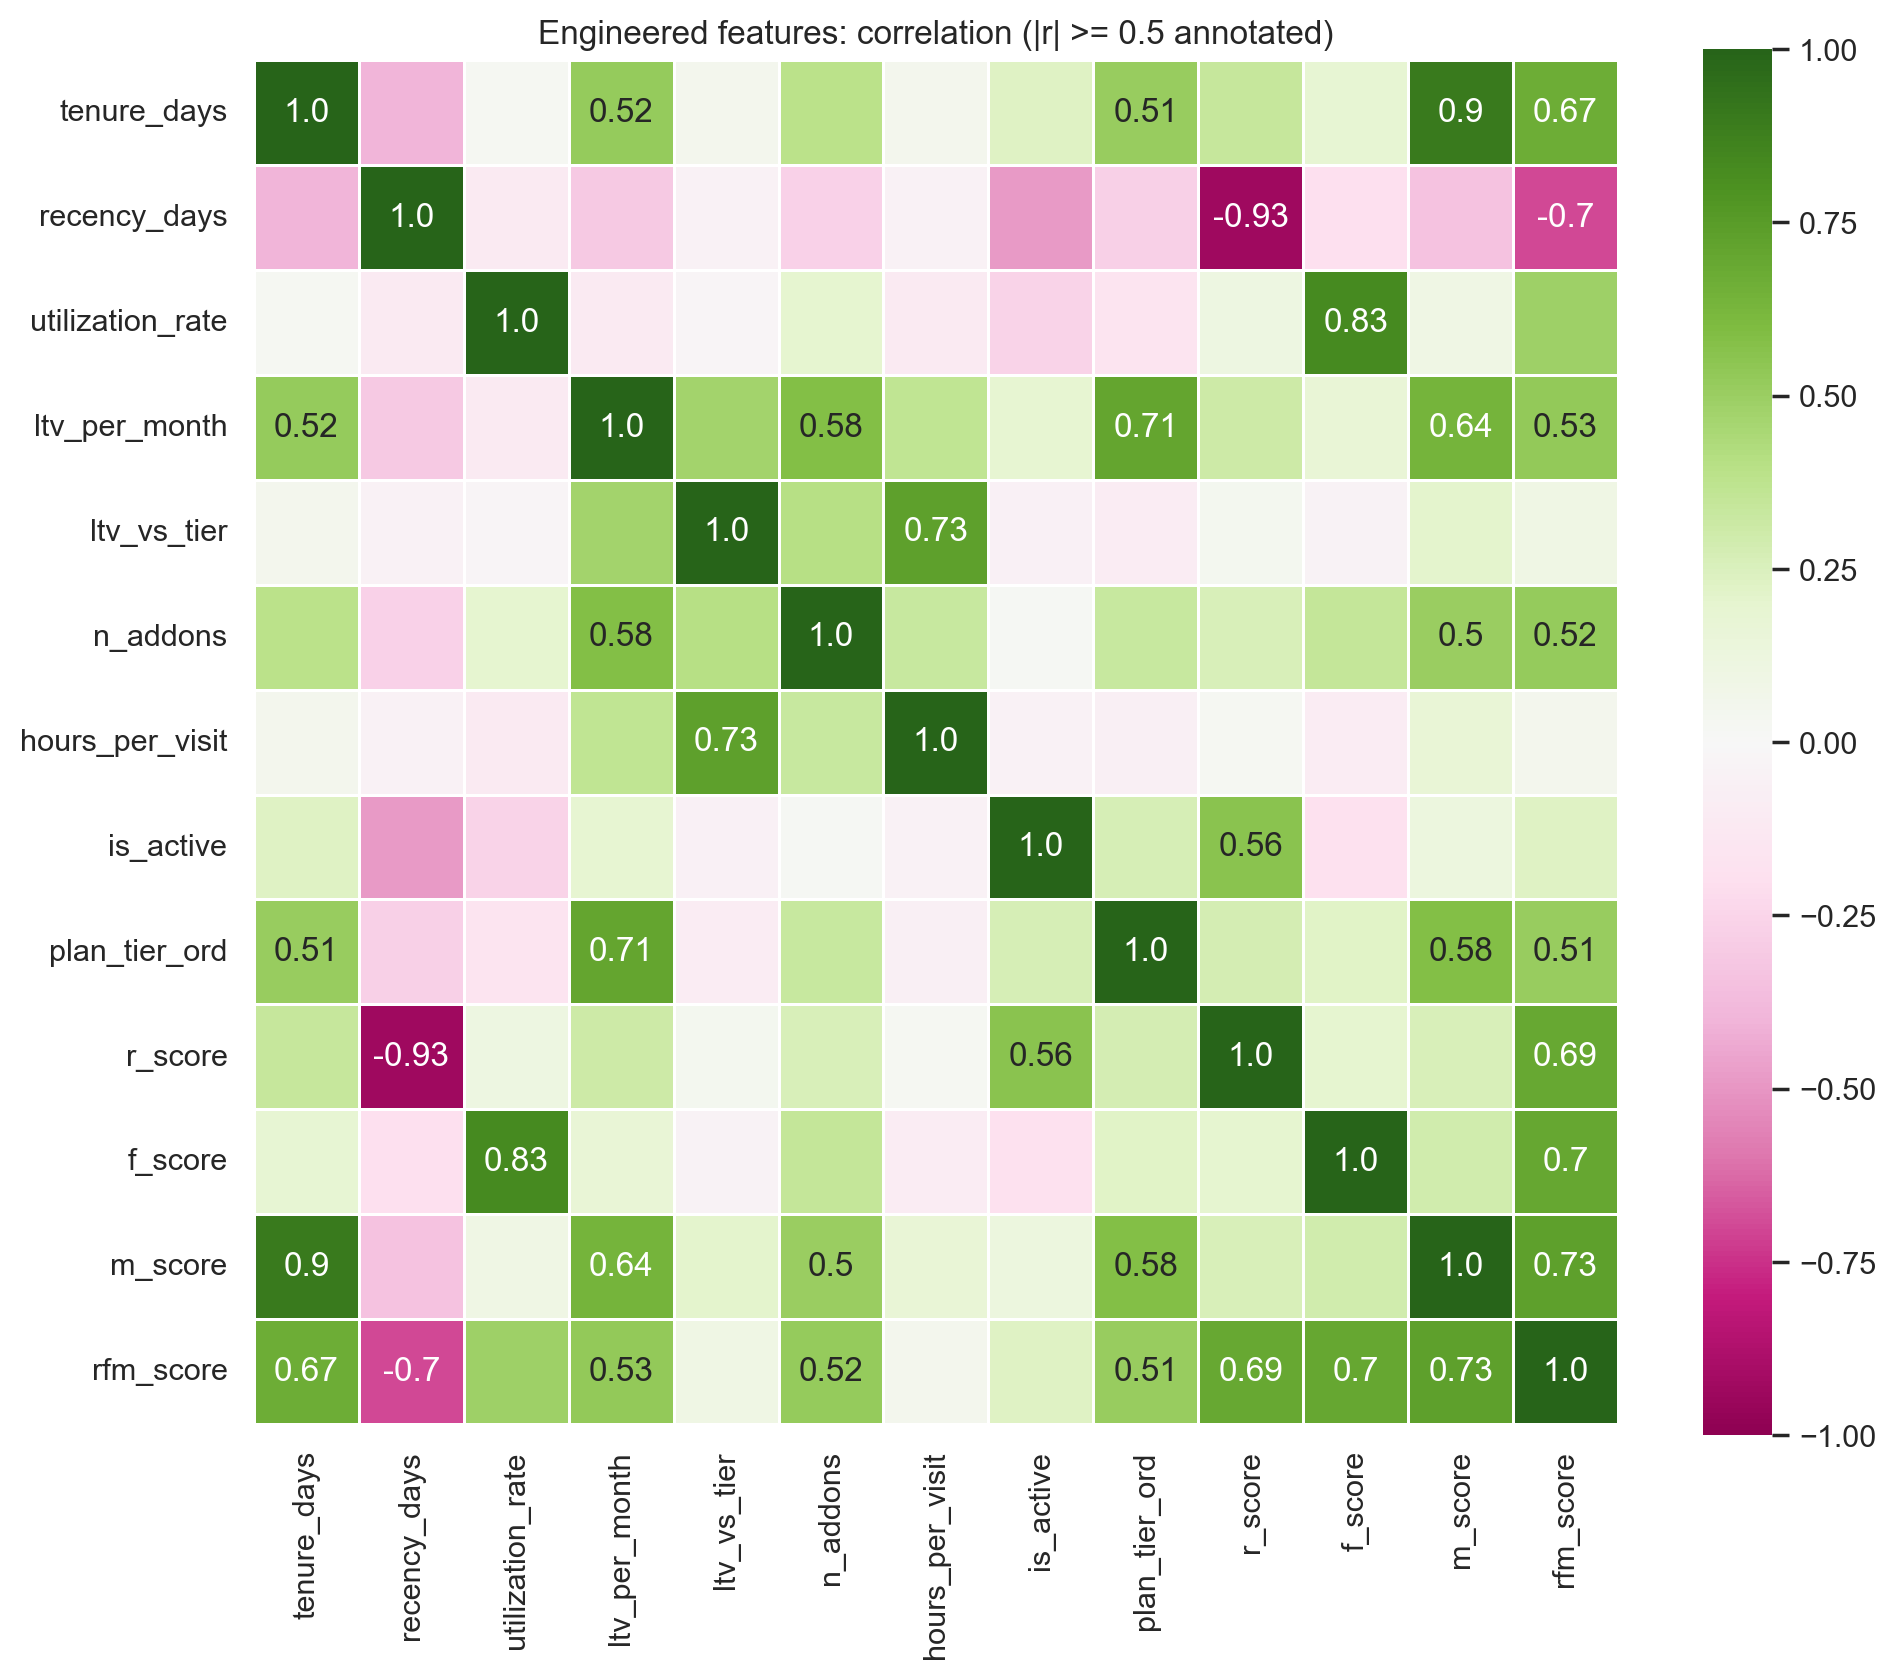

In [67]:
# Correlation among the engineered features: very high values mean redundancy (candidates to drop before clustering)
corr_fe = df_fe[engineered_features].replace([np.inf, -np.inf], np.nan).corr().round(2)

plt.figure(figsize=(11, 9))
sns.heatmap(corr_fe, center=0, cmap="PiYG", vmin=-1, vmax=1,
            annot=np.where(np.abs(corr_fe) >= 0.5, corr_fe.values, ""), fmt="s",
            square=True, linewidths=.5)
plt.title("Engineered features: correlation (|r| >= 0.5 annotated)")
plt.show()

### Main takeaways - possible groups

Hypotheses to confirm with the plots above (from the data-quality analysis):
- Most members never use add-ons, and a small group uses them a lot and pays 3-20 times the plan price: a "heavy add-on users" group (check `n_addons`, `hours_per_visit`, `ltv_vs_tier`).
- Plan tier is nearly a price list, so differences in value *within* a tier come from add-ons (`ltv_vs_tier`).
- Active and churned members should differ in recency and utilization.

Conclusions:
- *(fill in after running)* which engineered features separate the groups best
- *(fill in after running)* natural groupings suggested by the plots and the expected number of clusters (with the evidence)
- *(fill in after running)* challenges anticipated (skewness, outliers, redundancy such as `total_visits` vs `avg_weekly_visits`, imbalanced tiers)